# Predicting ciprofloxacin resistance in *Escherichia coli* from resistance genes and mutations

**Computing Bioinformatics: Group 1 project**

| Student no. | Name |
|---|---|
| 152502 | Kipkemboi Joy Chepchumba |
| 167998 | Kristein Gichuhi Mwaura |
| 166913 | Leriari Peter Tobiko |
| 161309 | Oringe Emmanuel Magunga |
| 167026 | Gichuru Victor Kimotho |

This notebook runs from top to bottom in Google Colab. It follows the eight stages in the project brief, and every stage ends with a short interpretation of our own results.

## 1. Question and objectives

**Research question.** Can known resistance genes and mutations in *E. coli* genomes predict ciprofloxacin resistance, and how much better is the prediction than a naive baseline?

**Hypothesis.** Resistant isolates carry more known resistance determinants. A model using genes plus mutations will outperform a genes-only model, and both will beat a majority-class baseline.

**Objectives**
1. Assemble and describe a labeled *E. coli* dataset with lab-measured ciprofloxacin phenotypes.
2. Identify genes and mutations associated with resistance, with multiple-testing correction.
3. Build and cross-validate classifiers against a majority-class baseline, comparing gene-only and gene + mutation features.
4. Interpret the top features biologically and compare them with the literature and CARD.

**Why this matters.** Ciprofloxacin is a fluoroquinolone used widely for urinary-tract and bloodstream infections caused by *E. coli*. Fluoroquinolones kill bacteria by trapping DNA gyrase (*gyrA*/*gyrB*) and topoisomerase IV (*parC*/*parE*) on DNA. Resistance comes mainly from **point mutations** in the quinolone-resistance-determining regions (QRDRs) of these target genes. It can also come from **acquired plasmid genes** (*qnr*, *aac(6')-Ib-cr*, *qepA*, *oqxAB*). Because the main mechanism is mutational, a gene presence/absence screen alone should miss much of the resistance. Our analysis tests exactly that.

## 2. Data acquisition

**Source:** [BV-BRC](https://www.bv-brc.org) (Bacterial and Viral Bioinformatics Resource Center, formerly PATRIC), queried through its public REST API. BV-BRC collects antimicrobial susceptibility test (AST) results from published studies and surveillance projects. It links them to whole-genome assemblies that it annotates with its own pipeline (RASTtk), and it screens the assemblies for AMR genes against the NCBI reference database (NDARO).

**Query:** all `genome_amr` records with `taxon_id = 562` (*E. coli*), `antibiotic = ciprofloxacin` and `evidence = Laboratory Method`. Records with `evidence = Computational Method` are BV-BRC's own predictions, so we exclude them because they would make the analysis circular.

The download script [`scripts/download_bvbrc.py`](https://github.com/eoringe/Bioinformatics/blob/main/scripts/download_bvbrc.py) produced the six CSV files below in `data/raw/`. The download takes about an hour, so the notebook loads the cached copies from the GitHub repository. Set `REDOWNLOAD = True` to rebuild them from the API.

In [1]:
import os, sys, subprocess, re, warnings
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/eoringe/Bioinformatics.git"
REDOWNLOAD = False

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython"], check=True)
    if not os.path.exists("Bioinformatics"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("Bioinformatics")
elif os.path.basename(os.getcwd()) in ("notebooks", "scripts"):
    os.chdir("..")

if REDOWNLOAD:
    subprocess.run([sys.executable, "scripts/download_bvbrc.py"], check=True)

DATA = "data/raw"
print("Working directory:", os.getcwd())
print("Data files:", sorted(f for f in os.listdir(DATA) if f.endswith(".csv")))

Working directory: C:\Users\Admin\Desktop\Bioinformatics-1
Data files: ['amr_genes.csv', 'amr_phenotypes.csv', 'genomes.csv', 'qrdr_features.csv', 'qrdr_sequences.csv', 'reference_qrdr.csv']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar
from Bio import Align
from Bio.Align import substitution_matrices

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
PAL = {"Resistant": "#c0392b", "Susceptible": "#2e86c1"}
RNG = 42

read = lambda f: pd.read_csv(os.path.join(DATA, f), dtype={"genome_id": str}, low_memory=False)
pheno_raw = read("amr_phenotypes.csv")
genomes_raw = read("genomes.csv")
genes_raw = read("amr_genes.csv")
feats_raw = read("qrdr_features.csv")
seqs_raw = read("qrdr_sequences.csv")
ref_raw = read("reference_qrdr.csv")

files = pd.DataFrame([
    ("amr_phenotypes.csv", "genome_amr", "One lab AST result per row (an isolate can have several)", pheno_raw),
    ("genomes.csv", "genome", "Assembly statistics and isolate metadata, one row per genome", genomes_raw),
    ("amr_genes.csv", "sp_gene (source = NDARO)", "AMR genes detected by BLAT homology against NCBI's curated AMR reference set", genes_raw),
    ("qrdr_features.csv", "genome_feature", "Annotated GyrA, ParC and ParE protein-coding genes in each genome", feats_raw),
    ("qrdr_sequences.csv", "feature_sequence", "Unique protein sequences for those genes, keyed by MD5", seqs_raw),
    ("reference_qrdr.csv", "genome_feature", "GyrA/ParC/ParE of reference strain E. coli K-12 MG1655 (genome 511145.12)", ref_raw),
], columns=["file", "BV-BRC endpoint", "content", "df"])
files["rows"] = files.df.map(len)
files["columns"] = files.df.map(lambda d: d.shape[1])
files.drop(columns="df")

,file,BV-BRC endpoint,content,rows,columns
0,amr_phenotypes.csv,genome_amr,One lab AST result per row (an isolate can hav...,16741,13
1,genomes.csv,genome,"Assembly statistics and isolate metadata, one ...",11780,18
2,amr_genes.csv,sp_gene (source = NDARO),AMR genes detected by BLAT homology against NC...,164633,11
3,qrdr_features.csv,genome_feature,"Annotated GyrA, ParC and ParE protein-coding g...",35448,8
4,qrdr_sequences.csv,feature_sequence,"Unique protein sequences for those genes, keye...",958,2
5,reference_qrdr.csv,genome_feature,GyrA/ParC/ParE of reference strain E. coli K-1...,3,7


**Variables used in the analysis**

| File | Variable | Meaning |
|---|---|---|
| amr_phenotypes | `genome_id` | BV-BRC genome identifier (taxon.version); links all files |
| | `resistant_phenotype` | Lab interpretation: Resistant / Intermediate / Susceptible (sometimes empty) |
| | `measurement_value`, `measurement_sign`, `measurement_unit` | MIC in mg/L (e.g. `<= 0.25`) or disk-zone diameter in mm |
| | `laboratory_typing_method` | MIC / broth dilution / agar dilution / disk diffusion |
| | `testing_standard`, `testing_standard_year` | Breakpoint guideline used (CLSI or EUCAST) and its version |
| | `pmid` | Publication the result came from |
| genomes | `genome_status`, `genome_quality`, `contigs`, `genome_length`, `gc_content` | Assembly quality |
| | `checkm_completeness`, `checkm_contamination` | Completeness and contamination estimated by CheckM |
| | `mlst` | Achtman 7-gene multilocus sequence type (e.g. `MLST.ecoli_achtman_4.131` = ST131) |
| | `isolation_country`, `host_common_name`, `collection_year`, `bioproject_accession` | Epidemiological metadata |
| amr_genes | `product` | Name of the matched AMR protein (e.g. `... => QnrS family`) |
| | `identity`, `query_coverage` | BLAT percentage identity and coverage against the reference protein |
| qrdr_features | `product`, `aa_length`, `aa_sequence_md5` | Which target protein, its length, and a hash used to fetch its sequence |
| qrdr_sequences / reference_qrdr | `sequence` | Amino-acid sequence |

In [3]:
for name, df in [("amr_phenotypes", pheno_raw), ("genomes", genomes_raw), ("amr_genes", genes_raw)]:
    print(f"--- {name}: first rows ---")
    display(df.head(3))

--- amr_phenotypes: first rows ---


,testing_standard,genome_id,genome_name,measurement_sign,antibiotic,resistant_phenotype,measurement_value,evidence,measurement,laboratory_typing_method,measurement_unit,pmid,testing_standard_year
0,EUCAST,562.100000,Escherichia coli c0fb0992-7bb9-11e9-a8d3-68b59...,NaN,ciprofloxacin,Intermediate,NaN,Laboratory Method,NaN,Disk diffusion,NaN,NaN,NaN
1,NaN,562.100000,Escherichia coli c0fb0992-7bb9-11e9-a8d3-68b59...,NaN,ciprofloxacin,NaN,6.0,Laboratory Method,6,Disk diffusion,mg/L,38219757,NaN
2,EUCAST,562.100001,Escherichia coli ca7bc2ea-7bb9-11e9-a8d3-68b59...,NaN,ciprofloxacin,Susceptible,NaN,Laboratory Method,NaN,Disk diffusion,NaN,NaN,NaN


--- genomes: first rows ---


,contigs,genome_status,genome_length,genome_quality,public,genome_id,mlst,gc_content,genome_name,isolation_country,collection_year,checkm_completeness,checkm_contamination,isolation_source,biosample_accession,host_common_name,bioproject_accession,assembly_accession
0,69,WGS,5091112,Good,True,562.100000,MLST.ecoli_achtman_4.131,50.822433,Escherichia coli c0fb0992-7bb9-11e9-a8d3-68b59...,Norway,2014.0,99.78,0.00,NaN,NaN,NaN,NaN,NaN
1,41,WGS,5078363,Good,True,562.100001,MLST.ecoli_achtman_4.998,50.311510,Escherichia coli ca7bc2ea-7bb9-11e9-a8d3-68b59...,Norway,2014.0,99.78,0.00,NaN,NaN,NaN,NaN,NaN
2,107,WGS,5147811,Good,True,562.100002,MLST.ecoli_achtman_4.141,50.573826,Escherichia coli ca96892c-7bb9-11e9-a8d3-68b59...,Norway,2014.0,99.78,0.22,NaN,NaN,NaN,NaN,NaN


--- amr_genes: first rows ---


,subject_coverage,query_coverage,source_id,source,evidence,genome_id,gene,product,identity,patric_id,classification
0,100,100,WP_000843414.1,NDARO,AMRFinderPlus: POINTP,562.100010,NaN,Multiple antibiotic resistance protein MarR,97,fig|562.100010.peg.1874,NaN
1,100,100,WP_000027057.1,NDARO,BLAT,562.100029,NaN,Class A beta-lactamase (EC 3.5.2.6) => TEM family,100,fig|562.100029.peg.4557,['']
2,100,100,WP_000027057.1,NDARO,AMRFinderPlus: ALLELEP,562.100029,NaN,Class A beta-lactamase (EC 3.5.2.6) => TEM family,100,fig|562.100029.peg.4557,NaN


**Interpretation.** The raw download has 16,741 lab AST records covering 11,780 genomes. The records come from several labs, test methods and breakpoint standards. Many records have a measurement but no R/S call, so Stage 3 has to harmonise the labels before we can use them.

## 3. Preprocessing and quality control

### 3a. Phenotype labels
Steps:
1. **Fill missing labels from raw measurements** (only for genomes without any reported label) using current EUCAST (v14, 2024) breakpoints for Enterobacterales and ciprofloxacin. For MICs: S ≤ 0.25 mg/L, R > 0.5 mg/L, and an MIC of 0.5 counts as intermediate. For 5 µg disk zones: S ≥ 25 mm, R < 22 mm.
2. **Collapse to one label per genome.** If an isolate has both R and S results, we drop it because its label is unreliable. We also drop isolates that are only "Intermediate", which turns the task into a clean R-vs-S problem.
3. **Biology check:** reported "Resistant" labels should have high MICs and reported "Susceptible" labels low MICs. We measure how often they agree.

In [4]:
def parse_value(v):
    try:
        return float(str(v).strip())
    except ValueError:
        return np.nan

ph = pheno_raw.copy()
ph["value"] = ph["measurement_value"].map(parse_value)
ph["sign"] = ph["measurement_sign"].fillna("=").str.strip()
ph["unit"] = ph["measurement_unit"].str.strip()
# NOTE: 2,733 disk-diffusion records store a zone diameter (mm) but are labelled "mg/L" in BV-BRC.
# We therefore decide MIC vs disk from the test method, not from the unit field.
is_disk = (ph.laboratory_typing_method == "Disk diffusion") | (ph.unit == "mm")
is_mic = ~is_disk & (ph.laboratory_typing_method.isin(["MIC", "Broth dilution", "Agar dilution"]) | (ph.unit == "mg/L"))
is_mic &= ph.value.between(0.001, 512)   # removes impossible values (one record says 1,000,000 mg/L)
is_disk &= ph.value.between(6, 50)
print(f"Disk-diffusion records whose unit field says mg/L: {((ph.laboratory_typing_method == 'Disk diffusion') & (ph.unit == 'mg/L')).sum()}")

def eucast_mic(v, s):
    if np.isnan(v):
        return np.nan
    if s in ("<=", "<") and v <= 0.25: return "Susceptible"
    if s in (">", ">=") and v >= 0.5:  return "Resistant"
    if s in ("=", "") or pd.isna(s):
        return "Susceptible" if v <= 0.25 else ("Resistant" if v > 0.5 else "Intermediate")
    if v <= 0.25: return "Susceptible"
    if v > 0.5:   return "Resistant"
    return np.nan

def eucast_disk(v):
    if np.isnan(v): return np.nan
    return "Susceptible" if v >= 25 else ("Resistant" if v < 22 else "Intermediate")

ph["eucast_call"] = np.where(is_mic, [eucast_mic(v, s) for v, s in zip(ph.value, ph.sign)],
                     np.where(is_disk, ph.value.map(eucast_disk), np.nan))
ph["eucast_call"] = ph["eucast_call"].replace("nan", np.nan)
# Reported labels take priority. A label derived from a measurement is used only for genomes with no reported label,
# so that different breakpoint versions do not create artificial R/S conflicts.
has_reported = ph.groupby("genome_id").resistant_phenotype.transform(lambda s: s.notna().any())
ph["label_source"] = np.select([ph.resistant_phenotype.notna(), ~has_reported & ph.eucast_call.notna()],
                               ["reported", "EUCAST from measurement"], "not used")
ph["label"] = np.where(ph.label_source == "reported", ph.resistant_phenotype,
                       np.where(ph.label_source == "EUCAST from measurement", ph.eucast_call, np.nan))
ph["label"] = ph["label"].replace("nan", np.nan)

print("Records by label source:\n", ph.label_source.value_counts().to_string())
print("\nRecord-level labels:\n", ph.label.value_counts(dropna=False).to_string())

Disk-diffusion records whose unit field says mg/L: 2733


Records by label source:
 label_source
reported                   9433
EUCAST from measurement    3821
not used                   3487

Record-level labels:
 label
Susceptible     8081
Resistant       4958
NaN             3487
Intermediate     215


In [5]:
# Biology check: do reported labels agree with the MIC under current EUCAST breakpoints?
chk = ph[(ph.label_source == "reported") & is_mic & ph.eucast_call.isin(["Resistant", "Susceptible"]) & ph.resistant_phenotype.isin(["Resistant", "Susceptible"])]
agree = pd.crosstab(chk.resistant_phenotype, chk.eucast_call, margins=True)
print(f"Reported label vs EUCAST-2024 interpretation of the same MIC (n = {len(chk)} records):")
display(agree)
disc = chk[chk.resistant_phenotype != chk.eucast_call]
print(f"Disagreement rate: {len(disc) / len(chk):.1%}")
print("Discordant records by testing standard / year:")
display(disc.groupby(["resistant_phenotype", "testing_standard", "testing_standard_year"], dropna=False).size().sort_values(ascending=False).head(8).to_frame("n"))
print("MIC values of discordant records:")
display(disc.groupby(["resistant_phenotype", "sign", "value"]).size().sort_values(ascending=False).head(8).to_frame("n"))

Reported label vs EUCAST-2024 interpretation of the same MIC (n = 2715 records):


eucast_call,Resistant,Susceptible,All
resistant_phenotype,,,
Resistant,958,4,962
Susceptible,12,1741,1753
All,970,1745,2715


Disagreement rate: 0.6%
Discordant records by testing standard / year:


,,,n
resistant_phenotype,testing_standard,testing_standard_year,
Susceptible,CLSI,NaN,11
Resistant,EUCAST,NaN,4
Susceptible,eucast,2015.0,1


MIC values of discordant records:


,,,n
resistant_phenotype,sign,value,
Susceptible,=,1.00,9
Resistant,=,0.12,3
Susceptible,<=,1.00,3
Resistant,=,0.25,1


In [6]:
# Collapse to one label per genome
lab = ph[ph.label.notna()].groupby("genome_id")["label"].agg(lambda s: set(s))
n0 = ph.genome_id.nunique()
conflict = lab[lab.map(lambda s: {"Resistant", "Susceptible"} <= s)]
only_I = lab[lab.map(lambda s: s == {"Intermediate"})]
def collapse(s):
    s = s - {"Intermediate"}
    return next(iter(s)) if len(s) == 1 else np.nan
y_all = lab.map(collapse).dropna()

qc_log = [("Genomes with any lab ciprofloxacin record", n0),
          ("  with no usable label (no phenotype, no measurement)", n0 - len(lab)),
          ("  with conflicting R and S results (dropped)", len(conflict)),
          ("  Intermediate only (dropped)", len(only_I)),
          ("Genomes with a clean R/S label", len(y_all))]
pd.DataFrame(qc_log, columns=["step", "genomes"])

,step,genomes
0,Genomes with any lab ciprofloxacin record,11780
1,"with no usable label (no phenotype, no measu...",187
2,with conflicting R and S results (dropped),26
3,Intermediate only (dropped),202
4,Genomes with a clean R/S label,11365


### 3b. Genome quality control
Even a perfect label is useless if the assembly behind it is poor. We keep genomes that are:
* `genome_quality` = Good (BV-BRC's own flag), where it is available;
* 4.3 to 6.3 Mb long, the normal *E. coli* range;
* ≤ 500 contigs;
* CheckM completeness ≥ 95% and contamination ≤ 5%, where available.

We also apply a **biological sanity check**. Every *E. coli* genome must contain *gyrA*, *parC* and *parE*, because they are essential housekeeping genes. A genome with no full-length copy of one of them is fragmented or mis-annotated, so we drop it.

In [7]:
g = genomes_raw.drop_duplicates("genome_id").set_index("genome_id")
g = g.loc[g.index.intersection(y_all.index)]
steps = [("Labelled genomes with metadata", len(g))]
for desc, mask in [
    ("genome_quality is Good (or missing)", g.genome_quality.fillna("Good").eq("Good")),
    ("length 4.3 to 6.3 Mb", g.genome_length.between(4.3e6, 6.3e6)),
    ("<= 500 contigs", g.contigs.fillna(0) <= 500),
    ("CheckM completeness >= 95 (or missing)", g.checkm_completeness.fillna(100) >= 95),
    ("CheckM contamination <= 5 (or missing)", g.checkm_contamination.fillna(0) <= 5),
]:
    g = g[mask.loc[g.index]]
    steps.append((desc, len(g)))
pd.DataFrame(steps, columns=["filter (cumulative)", "genomes remaining"])

,filter (cumulative),genomes remaining
0,Labelled genomes with metadata,11365
1,genome_quality is Good (or missing),11307
2,length 4.3 to 6.3 Mb,11305
3,<= 500 contigs,11246
4,CheckM completeness >= 95 (or missing),11239
5,CheckM contamination <= 5 (or missing),11230


### 3c. Calling QRDR mutations by sequence alignment
BV-BRC does not report point mutations, so we call them ourselves:
1. Take the GyrA, ParC and ParE protein sequences of every genome.
2. Align each unique sequence to the *E. coli* K-12 MG1655 reference protein. We use a global Needleman–Wunsch alignment with BLOSUM62, gap open −10 and gap extend −0.5.
3. Record every amino-acid substitution in reference numbering, e.g. `gyrA_S83L` means serine 83 → leucine.

We only use **full-length** proteins, defined as 95 to 105% of the reference length. Truncated copies at contig edges would otherwise create false "missing" residues.

In [8]:
GENE_OF = {"DNA gyrase subunit A (EC 5.99.1.3)": "gyrA",
           "DNA topoisomerase IV subunit A (EC 5.99.1.3)": "parC",
           "DNA topoisomerase IV subunit B (EC 5.99.1.3)": "parE"}
ref = ref_raw.drop_duplicates("gene").set_index("gene")["sequence"].to_dict()
print({k: len(v) for k, v in ref.items()})
print("Reference GyrA residues 81-90:", ref["gyrA"][80:90], " (S83 and D87 are the classic hot-spots)")
print("Reference ParC residues 78-86:", ref["parC"][77:86], " (S80 and E84)")

seq_of = seqs_raw.drop_duplicates("md5").set_index("md5")["sequence"].to_dict()
f = feats_raw[feats_raw.genome_id.isin(g.index)].copy()
f["gene"] = f["product"].map(GENE_OF)
f["seq"] = f["aa_sequence_md5"].map(seq_of)
f = f.dropna(subset=["gene", "seq"])
f["rel_len"] = f.seq.str.len() / f.gene.map(lambda x: len(ref[x]))
f["full_length"] = f.rel_len.between(0.95, 1.05)
print("\nCopies per genome (all annotated copies):")
display(f.groupby(["genome_id", "gene"]).size().unstack(fill_value=0).apply(lambda c: c.value_counts()).fillna(0).astype(int))
print("Fraction of annotated copies that are full length:", f.full_length.mean().round(4))

{'gyrA': 875, 'parC': 752, 'parE': 630}
Reference GyrA residues 81-90: GDSAVYDTIV  (S83 and D87 are the classic hot-spots)
Reference ParC residues 78-86: GDSACYEAM  (S80 and E84)

Copies per genome (all annotated copies):


gene,gyrA,parC,parE
0,3,0,1
1,11220,11223,11221
2,7,6,8
3,0,1,0


Fraction of annotated copies that are full length: 0.9992


In [9]:
aligner = Align.PairwiseAligner(mode="global", open_gap_score=-10, extend_gap_score=-0.5)
aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")

def substitutions(ref_seq, q):
    aln = aligner.align(ref_seq, q)[0]
    out = []
    for (rs, re_), (qs, qe) in zip(*aln.aligned):
        for i in range(re_ - rs):
            a, b = ref_seq[rs + i], q[qs + i]
            if a != b:
                out.append(f"{a}{rs + i + 1}{b}")
    return out

full = f[f.full_length]
uniq = full[["gene", "seq"]].drop_duplicates()
print(f"Aligning {len(uniq)} unique full-length protein sequences to K-12 ...")
subs_of = {(r.gene, r.seq): substitutions(ref[r.gene], r.seq) for r in uniq.itertuples()}
full = full.assign(subs=[subs_of[(a, b)] for a, b in zip(full.gene, full.seq)])

# A genome passes if it has >= 1 full-length copy of each target. When an assembly has two copies, take the union of their substitutions.
have = full.groupby("genome_id").gene.nunique()
ok_ids = have[have == 3].index
print(f"Genomes passing QC with full-length gyrA, parC and parE: {len(ok_ids)} of {len(g)}")
mut_long = full[full.genome_id.isin(ok_ids)].explode("subs").dropna(subset=["subs"])
mut_long["feature"] = mut_long.gene + "_" + mut_long.subs
M = pd.crosstab(mut_long.genome_id, mut_long.feature).clip(upper=1).reindex(ok_ids, fill_value=0)
print("Distinct substitutions observed:", M.shape[1])

# Sanity check on the reference itself: aligning K-12 to K-12 must give zero substitutions
assert all(len(substitutions(ref[k], ref[k])) == 0 for k in ref)

Aligning 757 unique full-length protein sequences to K-12 ...


Genomes passing QC with full-length gyrA, parC and parE: 11222 of 11230


Distinct substitutions observed: 813


### 3d. Acquired AMR genes
BV-BRC reports NDARO hits by protein product name, so we derive a short gene/family name from that text. Some NDARO hits are reference copies of **chromosomal housekeeping genes that every *E. coli* carries**: *gyrA*, *parC*, *parE*, *glpT*, *uhpT*, *ptsI*, *cyaA*, *marR* and the like. NCBI lists them because *point mutations* in them cause resistance, so their presence alone carries no information. We exclude (i) every hit that AMRFinderPlus flags as a point-mutation call (`evidence = POINTP`) and (ii) remaining copies of these chromosomal genes, matched by name. Our own mutation calls in 3c capture the target-gene effects. This keeps the "genes only" feature set strictly about **acquired** genes. We also drop unnamed "hypothetical protein" hits, hits below 80% identity or 80% coverage, and anything present in ≥ 95% of genomes.

In [10]:
CHROMOSOMAL = (r"DNA gyrase|topoisomerase IV|Glycerol-3-phosphate transporter|UhpT|Phosphoenolpyruvate-protein phosphotransferase|"
               r"Adenylate cyclase|MarR|hypothetical protein|Lipid A phosphoethanolamine|^Dihydropteroate synthase \(EC|Elongation factor|Translation elongation")
SHORT = [(r"\s*\(EC [^)]*\)", ""), (r"\s+family\b", ""), (r"Pentapeptide repeat protein\s+", ""),
         (r" fluoroquinolone-acetylating", ""), (r", quaternary ammonium compounds", ""), (r", extended-spectrum", ""),
         (r"Dihydropteroate synthase type-2.*", "Sul2"), (r"Dihydropteroate synthase type-1.*", "Sul1"),
         (r"Dihydropteroate synthase type-3.*", "Sul3"), (r"Quinolone resistance protein\s+", "")]

def gene_name(product):
    p = str(product)
    if "=>" in p:
        p = p.split("=>", 1)[1]
    p = p.split(" @ ")[0] if "Dihydropteroate" not in p else p
    for pat, rep in SHORT:
        p = re.sub(pat, rep, p)
    return p.strip()

gn = genes_raw[genes_raw.genome_id.isin(ok_ids)].copy()
n_hits = len(gn)
gn = gn[(gn.identity.fillna(0) >= 80) & (gn.query_coverage.fillna(0) >= 80)]
print(f"NDARO hits in QC-passed genomes: {n_hits}; after identity/coverage >= 80%: {len(gn)}")
point = gn["evidence"].astype(str).str.contains("POINT")
print(f"Hits that are AMRFinderPlus point-mutation calls (evidence = POINTP), removed: {point.sum()}")
print("  genes involved:", sorted(gn.loc[point, "product"].map(lambda p: re.sub(r"\s*\(EC [^)]*\)", "", p).split(" [")[0]).value_counts().head(12).index))
gn = gn[~point]
chrom = gn["product"].str.contains(CHROMOSOMAL, regex=True)
print("Chromosomal mutation-reference hits removed:")
print(gn.loc[chrom, "product"].map(lambda p: re.sub(r"\s*\(EC [^)]*\)", "", p)).value_counts().to_string())
gn = gn[~chrom]
gn["gene"] = gn["product"].map(gene_name)
G = pd.crosstab(gn.genome_id, gn.gene).clip(upper=1).reindex(ok_ids, fill_value=0)
too_common = G.columns[G.mean() >= 0.95].tolist()
G = G.drop(columns=too_common)
print(f"Also removed as near-universal (>= 95%): {too_common}")
print(f"Acquired-gene features kept: {G.shape[1]}")
QUIN_GENE = r"qnr|qep|oqx|-cr\b"
print("Acquired genes with a known quinolone mechanism:", sorted(c for c in G if re.search(QUIN_GENE, c, re.I)))
print("Most common acquired genes (% of genomes):")
print((G.mean() * 100).sort_values(ascending=False).head(12).round(1).to_string())

NDARO hits in QC-passed genomes: 155841; after identity/coverage >= 80%: 154827
Hits that are AMRFinderPlus point-mutation calls (evidence = POINTP), removed: 38376


  genes involved: ['Adenylate cyclase', 'Cell division protein FtsI', 'DNA gyrase subunit A', 'DNA topoisomerase IV subunit A', 'DNA topoisomerase IV subunit B', 'DNA-binding transcriptional dual regulator SoxS', 'Glycerol-3-phosphate transporter', 'Hexose phosphate transport protein UhpT', 'Multiple antibiotic resistance protein MarR', 'Oxygen-insensitive NADPH nitroreductase', 'Phosphoenolpyruvate-protein phosphotransferase of PTS system', 'Sensor protein BasS/PmrB (activates BasR/PmrA)']


Chromosomal mutation-reference hits removed:
product
hypothetical protein                                 1198
Dihydropteroate synthase                              770
Lipid A phosphoethanolamine transferase, putative     468


Also removed as near-universal (>= 95%): []
Acquired-gene features kept: 104
Acquired genes with a known quinolone mechanism: ["AAC(6')-Ib-cr", 'Qnr', 'QnrB', 'QnrB10']
Most common acquired genes (% of genomes):
gene
BlaEC                            91.9
Sul2                             48.1
TEM                              40.9
Dihydrofolate reductase          38.4
ANT(3'')-Ia (AadA)               37.6
APH(3'')-I                       33.0
APH(6)-Ic/APH(6)-Id              32.7
QacE delta 1                     30.5
CTX-M                            30.0
Tet(A)                           28.9
Mph(A)                           25.2
AAC(3)-II,III,IV,VI,VIII,IX,X    17.4


In [11]:
# Final analysis table
y = y_all.loc[ok_ids].map({"Resistant": 1, "Susceptible": 0}).astype(int)
meta = g.loc[ok_ids].copy()
meta["ST"] = meta.mlst.str.extract(r"(\d+)$")[0].fillna("unknown")
meta["phenotype"] = y.map({1: "Resistant", 0: "Susceptible"})

dups = meta.biosample_accession.dropna().duplicated().sum()
print(f"Duplicate BioSample accessions among kept genomes: {dups}")
if dups:
    keep = ~meta.biosample_accession.duplicated() | meta.biosample_accession.isna()
    meta = meta[keep]; y = y.loc[meta.index]; G = G.loc[meta.index]; M = M.loc[meta.index]

qc_summary = pd.DataFrame([
    ("raw phenotype records", len(pheno_raw)),
    ("genomes with any record", n0),
    ("genomes with a clean R/S label", len(y_all)),
    ("... passing assembly QC", len(g)),
    ("... with full-length gyrA/parC/parE", len(ok_ids)),
    ("... after removing duplicate BioSamples (FINAL)", len(y)),
], columns=["stage", "count"])
display(qc_summary)
print(f"Final dataset: {len(y)} genomes | Resistant {y.sum()} ({y.mean():.1%}) | Susceptible {(1 - y).sum()}")

Duplicate BioSample accessions among kept genomes: 2


,stage,count
0,raw phenotype records,16741
1,genomes with any record,11780
2,genomes with a clean R/S label,11365
3,... passing assembly QC,11230
4,... with full-length gyrA/parC/parE,11222
5,... after removing duplicate BioSamples (FINAL),11220


Final dataset: 11220 genomes | Resistant 4528 (40.4%) | Susceptible 6692


**Interpretation.** Preprocessing took the 16,741 raw records (11,780 genomes) down to a final, clean set of **11,220 genomes: 4,528 resistant (40.4%) and 6,692 susceptible**. That is far above the "few hundred" isolates we listed as a feasibility risk, and the classes are reasonably balanced. Things we found suspicious and handled:
* **Unit error in the source data.** 2,733 disk-diffusion records give a zone diameter in mm but are labelled "mg/L". Taken at face value, a 28 mm zone would read as an MIC of 28 mg/L and flip a susceptible isolate to "resistant". Our first pass did exactly that: it produced 2,408 genomes with conflicting labels. Deciding disk vs MIC from the test method fixed it and left only 26 genuine conflicts.
* **Breakpoint drift.** Reported labels agree with a fresh EUCAST-2024 reading of the same MIC for 99.4% of records. The 16 disagreements are almost all isolates with an MIC of exactly 1 mg/L called "Susceptible" under older CLSI breakpoints, before CLSI lowered the ciprofloxacin breakpoint in 2019. These borderline MICs will come back in the error analysis.
* **One impossible value** (an MIC of 1,000,000 mg/L) was excluded.
* **Biological sanity check.** 11,222 of 11,230 assemblies contain exactly the expected essential genes (one full-length copy each of *gyrA*, *parC* and *parE*), and aligning the K-12 reference to itself gives zero substitutions. Both results support the mutation-calling pipeline. We found 813 distinct substitutions across 757 unique protein sequences.
* **Point mutations disguised as genes.** 38,376 NDARO "gene" hits were really AMRFinderPlus point-mutation calls on chromosomal genes. Leaving them in would have leaked mutation information into the "genes only" model, so we removed them. 104 acquired-gene features remain. Only four of them have a direct quinolone mechanism (*aac(6')-Ib-cr*, *qnr*, *qnrB*, *qnrB10*), and no *qepA* or *oqxAB* was detected.

## 4. Exploratory data analysis

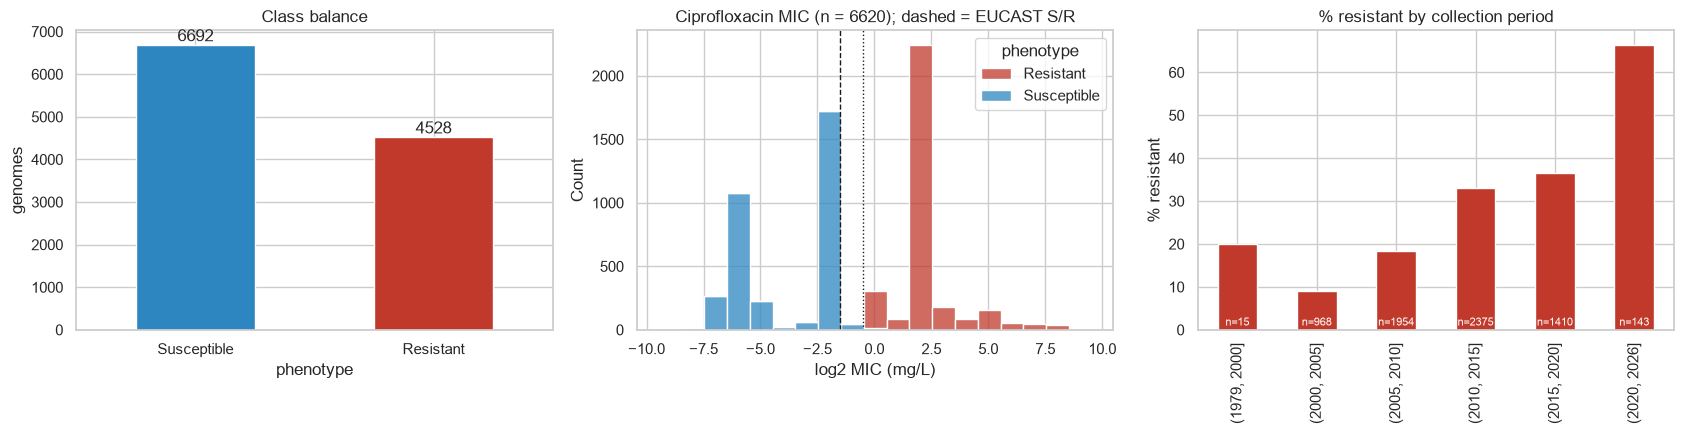

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
meta.phenotype.value_counts().plot.bar(ax=ax[0], color=[PAL[k] for k in meta.phenotype.value_counts().index])
ax[0].set_title("Class balance"); ax[0].set_ylabel("genomes"); ax[0].tick_params(axis="x", rotation=0)
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

# MIC distribution (one MIC per genome where available, exact values only)
mic = ph[is_mic & ph.genome_id.isin(meta.index) & ph.value.notna()].drop_duplicates("genome_id").set_index("genome_id")
mic = mic.assign(log2mic=np.log2(mic.value), phenotype=meta.phenotype.reindex(mic.index))
sns.histplot(data=mic, x="log2mic", hue="phenotype", palette=PAL, discrete=True, multiple="stack", ax=ax[1])
ax[1].axvline(np.log2(0.25) + 0.5, ls="--", c="k", lw=1); ax[1].axvline(np.log2(0.5) + 0.5, ls=":", c="k", lw=1)
ax[1].set_title(f"Ciprofloxacin MIC (n = {len(mic)}); dashed = EUCAST S/R"); ax[1].set_xlabel("log2 MIC (mg/L)")

yr = meta.collection_year.where(meta.collection_year.between(1980, 2026))
tab = pd.crosstab(pd.cut(yr, [1979, 2000, 2005, 2010, 2015, 2020, 2026]), meta.phenotype)
(tab.div(tab.sum(1), axis=0)["Resistant"] * 100).plot.bar(ax=ax[2], color=PAL["Resistant"])
ax[2].set_title("% resistant by collection period"); ax[2].set_ylabel("% resistant"); ax[2].set_xlabel("")
for i, n in enumerate(tab.sum(1)):
    ax[2].annotate(f"n={n}", (i, 1), ha="center", fontsize=8, color="white")
plt.tight_layout(); plt.show()

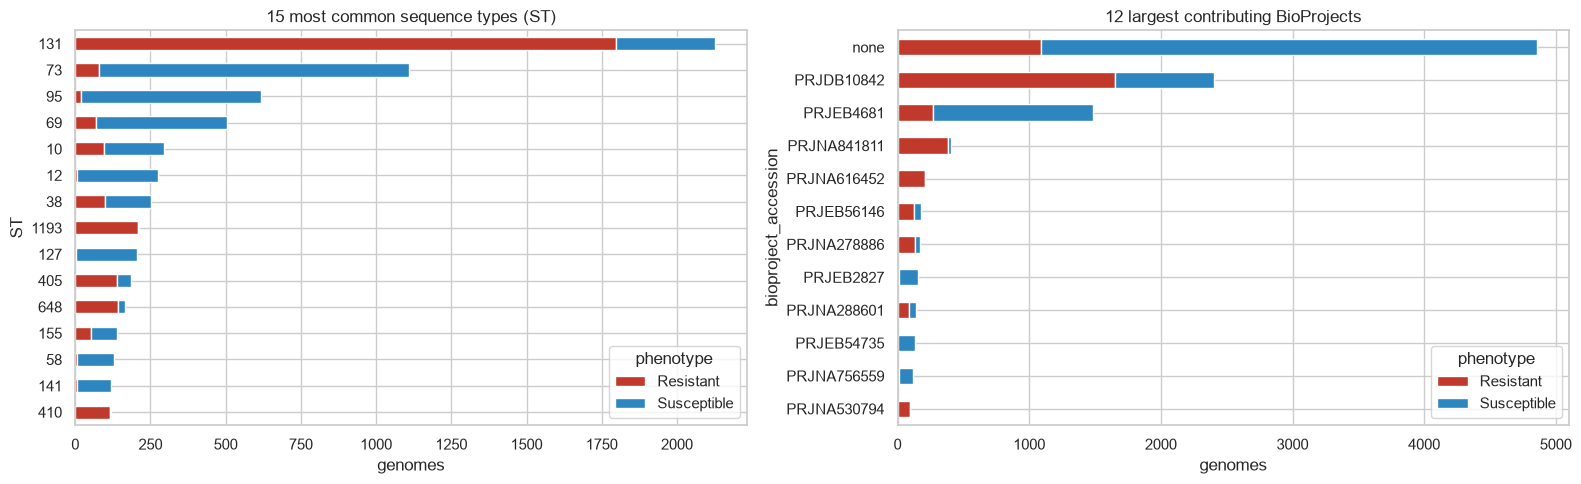

Distinct STs: 1004 | largest ST holds 19.0% of genomes
Distinct BioProjects: 48 | top 5 contribute 83.4%
Top countries: {'Norway': 3326, 'Japan': 2441, 'United Kingdom': 1568, 'England': 1080, 'China': 597, 'USA': 552, 'Germany': 287, 'Canada': 189}


In [13]:
# Sequence types and studies: is the dataset dominated by a few lineages or projects?
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
top_st = meta.ST.value_counts().head(15).index
st_tab = pd.crosstab(meta.ST, meta.phenotype).loc[top_st]
st_tab.plot.barh(stacked=True, color=PAL, ax=ax[0]); ax[0].invert_yaxis()
ax[0].set_title("15 most common sequence types (ST)"); ax[0].set_xlabel("genomes")
bp = pd.crosstab(meta.bioproject_accession.fillna("none"), meta.phenotype)
bp = bp.loc[bp.sum(1).sort_values(ascending=False).index[:12]]
bp.plot.barh(stacked=True, color=PAL, ax=ax[1]); ax[1].invert_yaxis()
ax[1].set_title("12 largest contributing BioProjects"); ax[1].set_xlabel("genomes")
plt.tight_layout(); plt.show()
print(f"Distinct STs: {meta.ST.nunique()} | largest ST holds {meta.ST.value_counts().iloc[0] / len(meta):.1%} of genomes")
print(f"Distinct BioProjects: {meta.bioproject_accession.nunique()} | top 5 contribute {bp.sum(1).head(5).sum() / len(meta):.1%}")
print("Top countries:", meta.isolation_country.value_counts().head(8).to_dict())

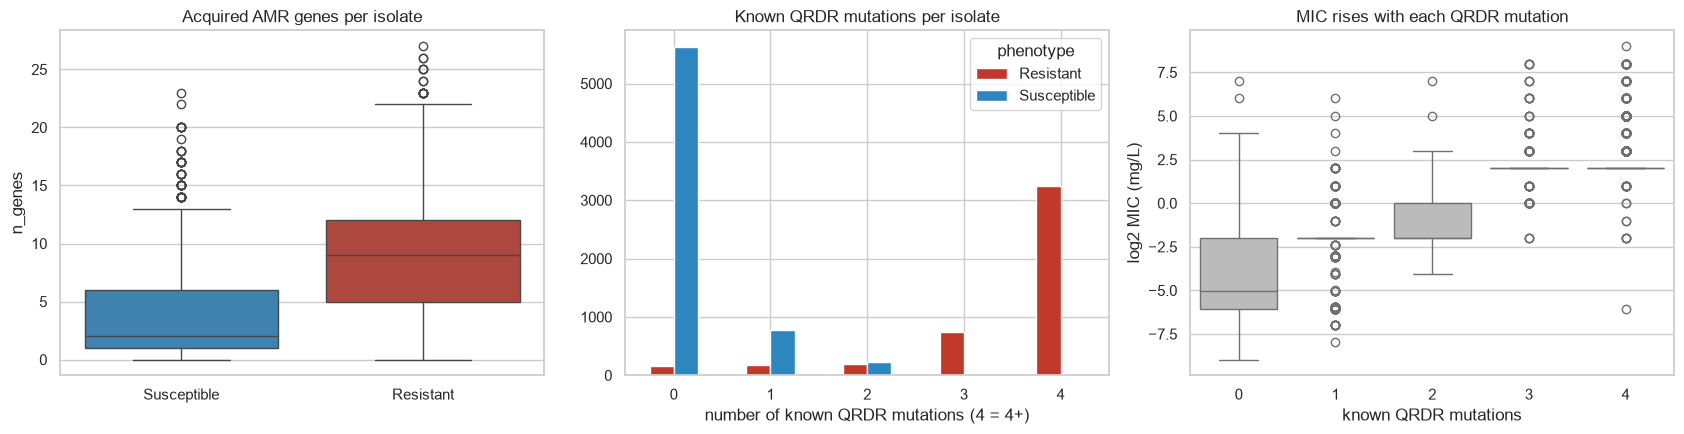

In [14]:
# Hypothesis part 1: do resistant isolates carry more known determinants?
KNOWN_QRDR = {  # Known fluoroquinolone resistance substitutions, as in CARD and the PointFinder E. coli database
    "gyrA": ["S83L", "S83A", "S83V", "S83W", "D87N", "D87G", "D87Y", "D87H", "D87V"],
    "parC": ["A56T", "S57T", "S80I", "S80R", "E84V", "E84K", "E84G", "E84A"],
    "parE": ["L416F", "L445H", "S458A", "S458T", "I529L", "I444F"],
}
known_feats = [f"{gname}_{s}" for gname, ss in KNOWN_QRDR.items() for s in ss]
M_known = M.reindex(columns=known_feats, fill_value=0)
meta["n_qrdr"] = M_known.sum(1)
meta["n_genes"] = G.sum(1)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=meta, x="phenotype", y="n_genes", palette=PAL, ax=ax[0], order=["Susceptible", "Resistant"])
ax[0].set_title("Acquired AMR genes per isolate"); ax[0].set_xlabel("")
ct = pd.crosstab(meta.n_qrdr.clip(upper=4), meta.phenotype)
ct.plot.bar(ax=ax[1], color=PAL); ax[1].set_title("Known QRDR mutations per isolate"); ax[1].set_xlabel("number of known QRDR mutations (4 = 4+)"); ax[1].tick_params(axis="x", rotation=0)
mm = mic.join(meta.n_qrdr).dropna(subset=["n_qrdr"])
sns.boxplot(data=mm, x=mm.n_qrdr.clip(upper=4).astype(int), y="log2mic", color="#bbbbbb", ax=ax[2])
ax[2].set_title("MIC rises with each QRDR mutation"); ax[2].set_xlabel("known QRDR mutations"); ax[2].set_ylabel("log2 MIC (mg/L)")
plt.tight_layout(); plt.show()

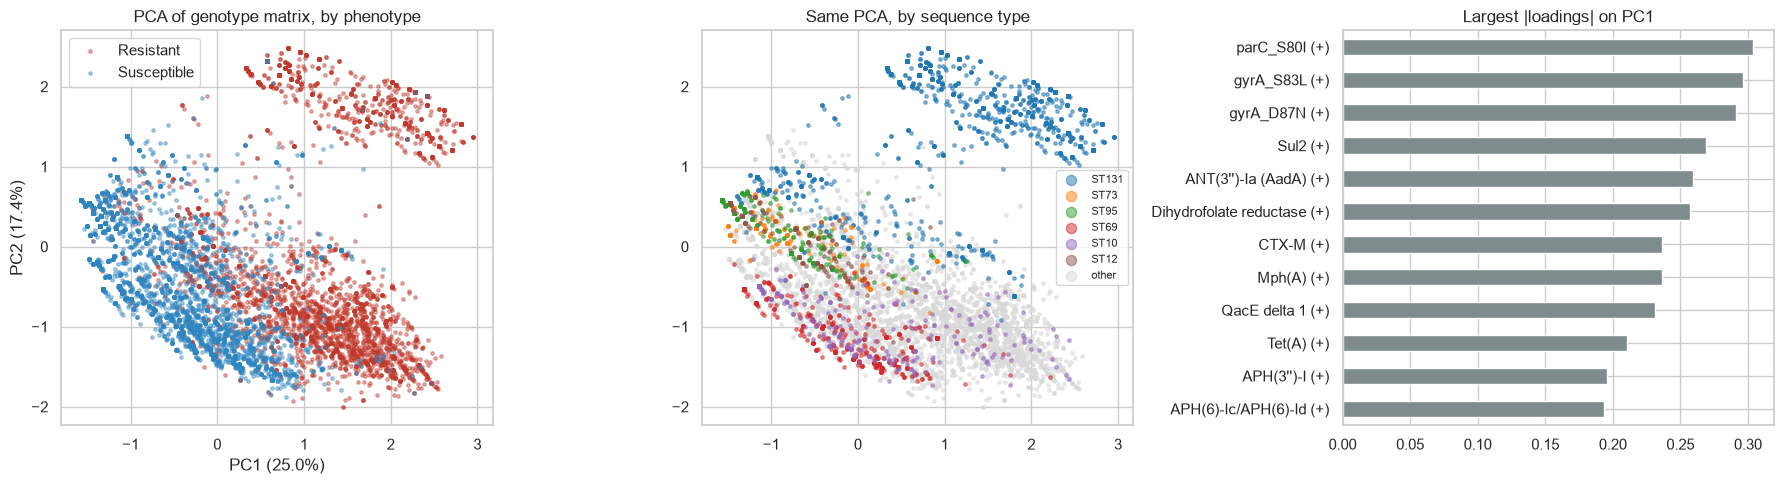

Explained variance, first 5 PCs: [0.25  0.174 0.08  0.051 0.044]


In [15]:
# PCA of the binary genotype matrix (genes + substitutions seen in >= 1% of isolates)
from sklearn.decomposition import PCA
X_eda = pd.concat([G, M], axis=1)
X_eda = X_eda.loc[:, X_eda.mean() >= 0.01]
pca = PCA(n_components=5, random_state=RNG).fit(X_eda - X_eda.mean())
pcs = pca.transform(X_eda - X_eda.mean())
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for lab_, c in PAL.items():
    m = (meta.phenotype == lab_).values
    ax[0].scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=.4, c=c, label=lab_)
ax[0].legend(); ax[0].set_title("PCA of genotype matrix, by phenotype")
ax[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
top5 = meta.ST.value_counts().head(6).index
st_col = meta.ST.where(meta.ST.isin(top5), "other")
for st_, c in zip(list(top5) + ["other"], sns.color_palette("tab10", 6) + [(.85, .85, .85)]):
    m = (st_col == st_).values
    ax[1].scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=.5, c=[c], label=f"ST{st_}" if st_ != "other" else "other", zorder=1 if st_ == "other" else 2)
ax[1].legend(markerscale=3, fontsize=8); ax[1].set_title("Same PCA, by sequence type")
load = pd.Series(pca.components_[0], index=X_eda.columns)
load.abs().sort_values().tail(12).rename(lambda c: f"{c} ({'+' if load[c] > 0 else '-'})").plot.barh(ax=ax[2], color="#7f8c8d")
ax[2].set_title("Largest |loadings| on PC1")
plt.tight_layout(); plt.show()
print("Explained variance, first 5 PCs:", np.round(pca.explained_variance_ratio_, 3))

**Interpretation.**
* **The MIC distribution is clearly bimodal.** Susceptible isolates sit at ≤ 0.015 to 0.25 mg/L, and resistant isolates pile up at 4 mg/L and above, the top of many test panels. The EUCAST breakpoint falls in the gap between the two modes, which is what we expect for a mutation-driven phenotype.
* **Resistance has risen over time** in this collection: about 9% of isolates from 2000 to 2005, about 33% from 2010 to 2015 and 66% from 2020 onwards (only 143 genomes in that last bin). Part of this is real, since fluoroquinolone resistance in *E. coli* has spread globally. Part is sampling: recent projects deliberately sequenced resistant clinical isolates.
* **The dataset is structured, not random.** It contains 1,004 sequence types, but **ST131 alone is 19% of genomes (84.5% resistant)**. The five largest BioProjects supply 83% of genomes, and Norway, Japan and the UK dominate, so Africa, including Kenya, is barely represented. This is exactly the "closely related isolates" risk from our minutes, and it is why Stage 7 also uses ST-grouped cross-validation.
* **Determinant counts already separate the classes.** Resistant isolates carry a median of 9 acquired AMR genes vs 2 in susceptible ones. The QRDR mutation count is even sharper: 5,628 of 6,692 susceptible isolates have none, while most resistant isolates have 4 or more. The MIC climbs stepwise with each extra mutation. This is the classic picture: a first *gyrA* mutation gives low-level resistance, and each additional *gyrA*/*parC* mutation raises it further.
* **PCA** of the binary genotype matrix (PC1 25%, PC2 17%) separates resistant from susceptible isolates along PC1. PC1 is loaded by *parC* S80I, *gyrA* S83L/D87N and a block of multidrug-resistance genes (*sul2*, *aadA*, *dfr*, *bla*CTX-M, *mph(A)*). ST131 forms its own tight cluster. So genotype space is shaped by both mechanism and lineage.

## 5. Core analysis: which genes and mutations are associated with resistance?

For each feature present in at least 10 genomes we build a 2×2 table (feature present/absent × R/S) and run:
* a **Fisher exact test** (two-sided),
* an **odds ratio** with Haldane–Anscombe correction (+0.5 in each cell) and a 95% Wald CI,
* **Benjamini–Hochberg FDR** correction across all tests.

We also test hypothesis part 1 formally: do resistant isolates carry more determinants? We use a Mann–Whitney U test and report the rank-biserial effect size.

In [16]:
def assoc_table(X, y, kind):
    rows = []
    yb = y.values.astype(bool)
    for c in X.columns:
        x = X[c].values.astype(bool)
        a, b = (x & yb).sum(), (x & ~yb).sum()
        c_, d = (~x & yb).sum(), (~x & ~yb).sum()
        _, p = stats.fisher_exact([[a, b], [c_, d]])
        or_ = ((a + .5) * (d + .5)) / ((b + .5) * (c_ + .5))
        se = np.sqrt(1/(a+.5) + 1/(b+.5) + 1/(c_+.5) + 1/(d+.5))
        rows.append((c, kind, a, b, a / yb.sum(), b / (~yb).sum(), or_, np.exp(np.log(or_) - 1.96*se), np.exp(np.log(or_) + 1.96*se), p))
    return pd.DataFrame(rows, columns=["feature", "type", "n_R_with", "n_S_with", "prev_R", "prev_S", "odds_ratio", "OR_low", "OR_high", "p"])

MIN_N = 10
Gt = G.loc[:, G.sum() >= MIN_N]
Mt = M.loc[:, M.sum() >= MIN_N]
res = pd.concat([assoc_table(Gt, y, "acquired gene"), assoc_table(Mt, y, "substitution")], ignore_index=True)
res["q_BH"] = multipletests(res.p, method="fdr_bh")[1]
res["log2OR"] = np.log2(res.odds_ratio)
res["known_QRDR"] = res.feature.isin(known_feats)
res = res.sort_values("p")
sig = res[res.q_BH < 0.05]
print(f"Tests run: {len(res)} ({len(Gt.columns)} genes, {len(Mt.columns)} substitutions). Significant at FDR 5%: {len(sig)} "
      f"({(sig.log2OR > 0).sum()} enriched in R, {(sig.log2OR < 0).sum()} enriched in S)")
fmt = {"prev_R": "{:.1%}", "prev_S": "{:.1%}", "odds_ratio": "{:.1f}", "OR_low": "{:.1f}", "OR_high": "{:.1f}", "p": "{:.1e}", "q_BH": "{:.1e}", "log2OR": "{:.2f}"}
display(res.head(25).style.format(fmt).hide(axis="index"))

Tests run: 160 (61 genes, 99 substitutions). Significant at FDR 5%: 137 (92 enriched in R, 45 enriched in S)


feature,type,n_R_with,n_S_with,prev_R,prev_S,odds_ratio,OR_low,OR_high,p,q_BH,log2OR,known_QRDR
ANT(3'')-Ia (AadA),acquired gene,2688,1534,59.4%,22.9%,4.9,4.5,5.3,0.0e+00,0.0e+00,2.30,False
CTX-M,acquired gene,2839,525,62.7%,7.8%,19.7,17.7,22.0,0.0e+00,0.0e+00,4.30,False
Dihydrofolate reductase,acquired gene,2812,1495,62.1%,22.3%,5.7,5.2,6.2,0.0e+00,0.0e+00,2.51,False
Mph(A),acquired gene,2270,560,50.1%,8.4%,11.0,9.9,12.2,0.0e+00,0.0e+00,3.46,False
gyrA_S83L,substitution,4336,670,95.8%,10.0%,202.3,171.6,238.6,0.0e+00,0.0e+00,7.66,True
parC_A192V,substitution,1741,232,38.4%,3.5%,17.4,15.0,20.0,0.0e+00,0.0e+00,4.12,False
parC_A471G,substitution,1745,232,38.5%,3.5%,17.4,15.1,20.1,0.0e+00,0.0e+00,4.12,False
gyrA_D87N,substitution,3795,63,83.8%,0.9%,540.2,416.8,700.3,0.0e+00,0.0e+00,9.08,True
parC_S80I,substitution,3979,50,87.9%,0.7%,952.6,712.2,1274.2,0.0e+00,0.0e+00,9.90,True
parC_E84V,substitution,1713,10,37.8%,0.1%,387.3,210.8,711.6,0.0e+00,0.0e+00,8.60,True


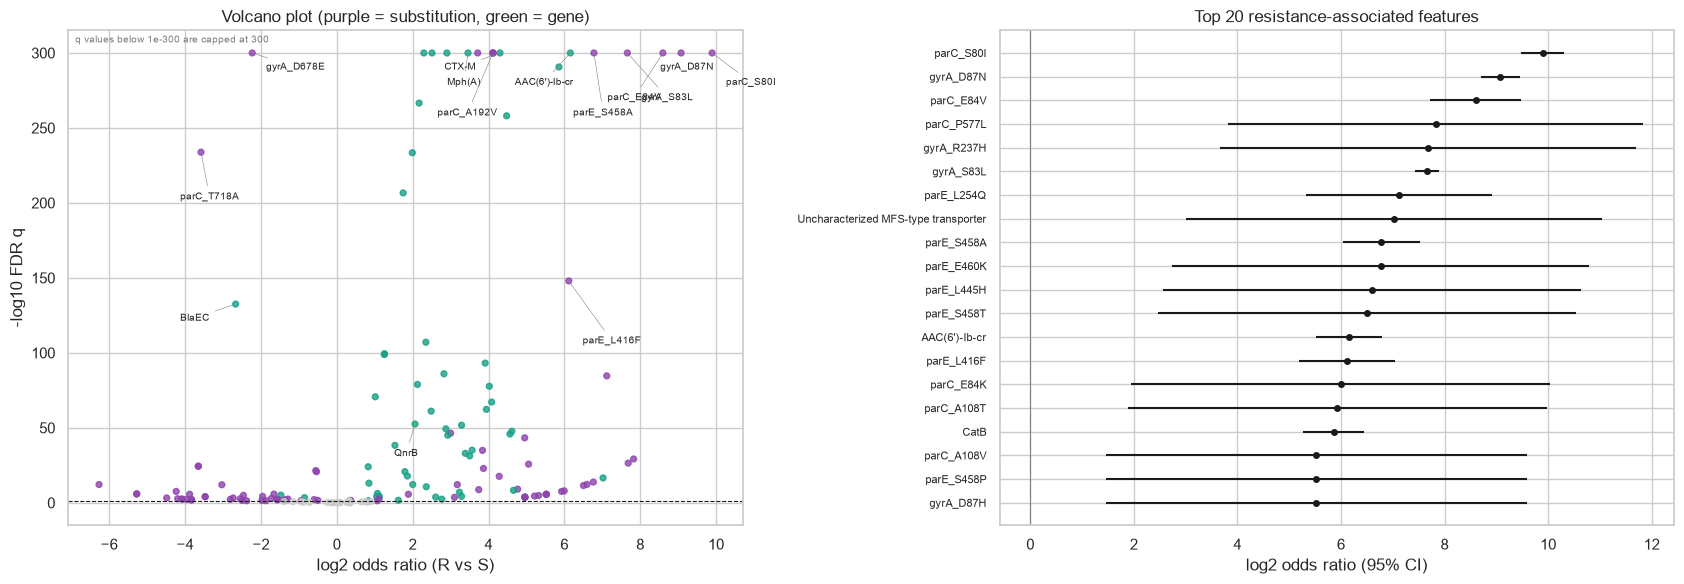

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
res_p = res.assign(mlq=-np.log10(res.q_BH.clip(lower=1e-300)))
colors = np.where(res_p.q_BH >= 0.05, "#cccccc", np.where(res_p.type == "substitution", "#8e44ad", "#16a085"))
ax[0].scatter(res_p.log2OR, res_p.mlq, c=colors, s=18, alpha=.8)
label_feats = ["parC_S80I", "gyrA_D87N", "parC_E84V", "gyrA_S83L", "parE_S458A", "AAC(6')-Ib-cr", "CTX-M", "Mph(A)",
               "parC_A192V", "gyrA_D678E", "parC_T718A", "BlaEC", "QnrB", "parE_L416F"]
for k, (_, r) in enumerate(res_p[res_p.feature.isin(label_feats)].iterrows()):
    ax[0].annotate(r.feature, (r.log2OR, r.mlq), fontsize=7.5, xytext=(-40 + 25 * (k % 3), -12 - 11 * (k % 4)),
                   textcoords="offset points", arrowprops=dict(arrowstyle="-", lw=.4, color="grey"))
ax[0].text(0.01, 0.99, "q values below 1e-300 are capped at 300", transform=ax[0].transAxes, fontsize=7, va="top", color="grey")
ax[0].axhline(-np.log10(0.05), ls="--", c="k", lw=.8)
ax[0].set_xlabel("log2 odds ratio (R vs S)"); ax[0].set_ylabel("-log10 FDR q"); ax[0].set_title("Volcano plot (purple = substitution, green = gene)")

top = res[res.q_BH < 0.05].sort_values("odds_ratio", ascending=False).head(20).iloc[::-1]
ax[1].errorbar(top.log2OR, range(len(top)), xerr=[top.log2OR - np.log2(top.OR_low), np.log2(top.OR_high) - top.log2OR], fmt="o", c="k", ms=4)
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels(top.feature, fontsize=8); ax[1].axvline(0, c="grey", lw=.8)
ax[1].set_xlabel("log2 odds ratio (95% CI)"); ax[1].set_title("Top 20 resistance-associated features")
plt.tight_layout(); plt.show()

In [18]:
def mwu(col):
    r_, s_ = meta.loc[y == 1, col], meta.loc[y == 0, col]
    U, p = stats.mannwhitneyu(r_, s_, alternative="greater")
    return dict(measure=col, median_R=r_.median(), median_S=s_.median(), mean_R=r_.mean(), mean_S=s_.mean(), U=U, p=p, rank_biserial=2 * U / (len(r_) * len(s_)) - 1)
meta["n_determinants"] = meta.n_genes + meta.n_qrdr
display(pd.DataFrame([mwu("n_genes"), mwu("n_qrdr"), mwu("n_determinants")]).style.format({"p": "{:.1e}", "mean_R": "{:.2f}", "mean_S": "{:.2f}", "rank_biserial": "{:.2f}", "U": "{:.0f}"}).hide(axis="index"))

# Genotype-to-phenotype summary: resistance rate by number of known QRDR mutations
gp = pd.crosstab(meta.n_qrdr.clip(upper=4), meta.phenotype)
gp["% resistant"] = (gp.Resistant / gp.sum(1) * 100).round(1)
gp.index.name = "known QRDR mutations (4 = 4+)"
display(gp)

measure,median_R,median_S,mean_R,mean_S,U,p,rank_biserial
n_genes,9.000000,2.000000,8.75,3.70,24733628,0.0e+00,0.63
n_qrdr,4.000000,0.000000,3.89,0.21,29491970,0.0e+00,0.95
n_determinants,13.000000,2.000000,12.64,3.91,27944336,0.0e+00,0.84


phenotype,Resistant,Susceptible,% resistant
known QRDR mutations (4 = 4+),,,
0,151,5628,2.6
1,184,780,19.1
2,201,235,46.1
3,741,23,97.0
4,3251,26,99.2


**Interpretation.** Of 160 features tested (61 acquired genes, 99 substitutions), **137 are significant after FDR correction: 92 enriched in resistant and 45 in susceptible isolates**.
* **The strongest associations are the textbook target mutations.** *parC* S80I has an odds ratio of about 950 (87.9% of R vs 0.7% of S), *gyrA* D87N about 540, *parC* E84V about 390, *gyrA* S83L about 200 (95.8% vs 10.0%) and *parE* S458A about 110. The plasmid gene *aac(6')-Ib-cr* is the strongest acquired gene (OR ≈ 71, 18.0% vs 0.3%).
* **Many acquired genes with no quinolone activity are also strongly associated**, for example the ESBL *bla*CTX-M (OR ≈ 20; 62.7% vs 7.8%), *mph(A)*, *aac(3)*, *sul2* and *tet(A)*. They are markers of multidrug-resistant plasmids and clones rather than causes of ciprofloxacin resistance. This is the **co-resistance** problem we examine in Stage 6.
* **Not every catalogued mutation is predictive here.** *gyrA* D87G (OR 1.2, q = 0.59) and *parC* S57T (OR 1.3) are not meaningfully enriched, and *gyrA* S83A is actually more common in susceptible isolates. A single mutation like these gives only low-level resistance that often stays below the breakpoint, and S57T is a known lineage polymorphism.
* **Some substitutions are enriched in susceptible isolates**, e.g. *gyrA* D678E (61.1% of S vs 25.1% of R) and *parC* T718A. They sit far from the QRDR and are almost certainly phylogenetic markers of mostly-susceptible lineages, not protective mutations.
* **Hypothesis part 1 is supported.** Resistant isolates carry more determinants: a median of 13 vs 2 in total (Mann–Whitney p < 10⁻³⁰⁰, rank-biserial r = 0.84). The difference is much larger for QRDR mutations (r = 0.95) than for acquired genes (r = 0.63). The genotype-to-phenotype table shows a clear threshold: 2.6% of isolates with 0 known QRDR mutations are resistant, 19% with 1, 46% with 2 and **97 to 99% with 3 or more**.

## 6. Biological interpretation

We interpret the results with two methods:
1. **Mechanism annotation against CARD and the literature.** We assign each significant feature to a resistance mechanism as CARD's Antibiotic Resistance Ontology defines them: target alteration, target protection, antibiotic inactivation, efflux, or "other drug class". The "other drug class" features are associated with resistance but are not known to act on fluoroquinolones. We then test whether quinolone-specific mechanisms are over-represented among the strongest hits.
2. **Co-occurrence network (NetworkX).** Nodes are the 30 most significant resistance-enriched features (lowest FDR q). Two nodes are linked when the features co-occur across isolates (phi correlation ≥ 0.3). Connected communities reveal determinants that travel together, on the same plasmid or in the same clone.

In [19]:
def mechanism(feat):
    f_ = feat.lower()
    if feat in known_feats:                         return "Target alteration (known QRDR mutation)"
    if re.match(r"(gyra|parc|pare)_", f_):           return "Target-gene polymorphism (not in CARD list)"
    if "qnr" in f_:                                  return "Target protection (Qnr)"
    if "-cr" in f_ or "ib-cr" in f_:                 return "Antibiotic inactivation (AAC(6')-Ib-cr)"
    if re.search(r"qep|oqx", f_):                    return "Efflux (QepA/OqxAB)"
    return "Other drug class (co-resistance)"

sig_r = res[(res.q_BH < 0.05) & (res.log2OR > 0)].copy()
sig_r["mechanism"] = sig_r.feature.map(mechanism)
res["mechanism"] = res.feature.map(mechanism)
print(f"{len(sig_r)} features significantly enriched in resistant isolates, by mechanism:")
display(sig_r.groupby("mechanism").agg(n=("feature", "size"), median_OR=("odds_ratio", "median"), examples=("feature", lambda s: ", ".join(s.head(6)))).sort_values("median_OR", ascending=False))

# Are known quinolone mechanisms enriched among the top-ranked hits?
quin_mech = lambda m: not m.startswith("Other") and not m.startswith("Target-gene polymorphism")
top_k = 20
ranked = sig_r.sort_values("odds_ratio", ascending=False)
in_top = ranked.head(top_k).mechanism.map(quin_mech).sum()
in_rest = ranked.iloc[top_k:].mechanism.map(quin_mech).sum()
tbl = [[in_top, top_k - in_top], [in_rest, max(len(ranked) - top_k, 0) - in_rest]]
odds, p_enr = stats.fisher_exact(tbl, alternative="greater") if len(ranked) > top_k else (np.nan, np.nan)
print(f"Quinolone-specific mechanisms: {in_top}/{top_k} of the top-{top_k} features by OR vs {in_rest}/{max(len(ranked)-top_k,0)} of the rest (one-sided Fisher p = {p_enr:.2g})")

92 features significantly enriched in resistant isolates, by mechanism:


,n,median_OR,examples
mechanism,,,
Antibiotic inactivation (AAC(6')-Ib-cr),1,71.371602,AAC(6')-Ib-cr
Target alteration (known QRDR mutation),16,66.607756,"gyrA_S83L, gyrA_D87N, parC_S80I, parC_E84V, pa..."
Target-gene polymorphism (not in CARD list),26,29.178189,"parC_A192V, parC_A471G, parC_Q481H, parE_L254Q..."
Other drug class (co-resistance),47,6.812684,"ANT(3'')-Ia (AadA), CTX-M, Dihydrofolate reduc..."
Target protection (Qnr),2,3.139809,"QnrB, QnrB10"


Quinolone-specific mechanisms: 11/20 of the top-20 features by OR vs 8/72 of the rest (one-sided Fisher p = 9.7e-05)


In [20]:
# Literature/CARD comparison: how often is each known QRDR mutation seen, and how predictive is it?
kn = res[res.known_QRDR].set_index("feature")[["n_R_with", "n_S_with", "prev_R", "prev_S", "odds_ratio", "q_BH"]]
missing_known = [k for k in known_feats if k not in M.columns or M[k].sum() < MIN_N]
display(kn.sort_values("n_R_with", ascending=False).style.format({"prev_R": "{:.1%}", "prev_S": "{:.1%}", "odds_ratio": "{:.1f}", "q_BH": "{:.1e}"}))
print("Known CARD/PointFinder mutations seen in < 10 genomes (not tested):", missing_known)
novel = res[(res.q_BH < 0.05) & (res.log2OR > 1) & (res.type == "substitution") & ~res.known_QRDR].head(10)
print("\nSignificant target-gene substitutions NOT in the known list (candidates for lineage markers or novel effects):")
display(novel[["feature", "prev_R", "prev_S", "odds_ratio", "q_BH"]].style.format(fmt).hide(axis="index"))

,n_R_with,n_S_with,prev_R,prev_S,odds_ratio,q_BH
feature,,,,,,
gyrA_S83L,4336,670,95.8%,10.0%,202.3,0.0e+00
parC_S80I,3979,50,87.9%,0.7%,952.6,0.0e+00
gyrA_D87N,3795,63,83.8%,0.9%,540.2,0.0e+00
parE_I529L,1797,319,39.7%,4.8%,13.1,0.0e+00
parC_E84V,1713,10,37.8%,0.1%,387.3,0.0e+00
parE_S458A,872,14,19.3%,0.2%,109.9,0.0e+00
parE_L416F,406,9,9.0%,0.1%,69.4,1.1e-148
parC_S57T,160,188,3.5%,2.8%,1.3,3.7e-02
parC_E84G,132,6,2.9%,0.1%,31.0,4.7e-44


Known CARD/PointFinder mutations seen in < 10 genomes (not tested): ['gyrA_S83V', 'gyrA_S83W', 'gyrA_D87V', 'parC_E84A', 'parE_I444F']

Significant target-gene substitutions NOT in the known list (candidates for lineage markers or novel effects):


feature,prev_R,prev_S,odds_ratio,q_BH
parC_A192V,38.4%,3.5%,17.4,0.0e+00
parC_A471G,38.5%,3.5%,17.4,0.0e+00
parC_Q481H,38.6%,3.5%,17.3,0.0e+00
parE_L254Q,4.9%,0.0%,138.9,2.3e-85
parE_T172A,4.7%,0.6%,8.0,3.6e-47
parC_P577L,1.7%,0.0%,226.9,6.1e-30
gyrA_R237H,1.5%,0.0%,205.6,3.7e-27
parC_A620V,1.7%,0.0%,33.3,1.7e-26
parE_V153I,1.3%,0.1%,19.4,2.2e-18
parE_E460K,0.8%,0.0%,108.7,1.5e-14


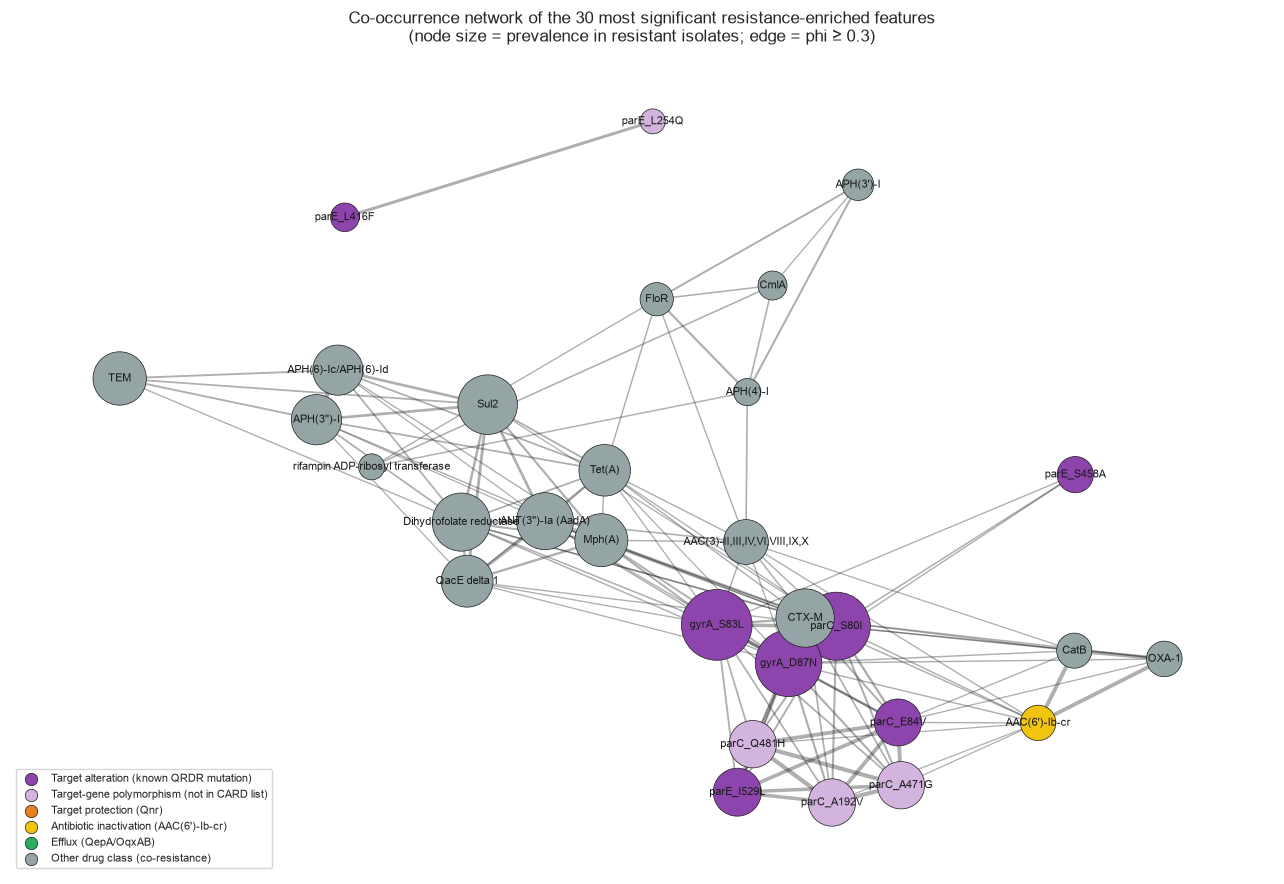

Nodes 30, edges 130, communities 5
  community 1 (10): ['CTX-M', 'gyrA_D87N', 'gyrA_S83L', 'parC_A192V', 'parC_A471G', 'parC_E84V', 'parC_Q481H', 'parC_S80I', 'parE_I529L', 'parE_S458A']
  community 2 (9): ["ANT(3'')-Ia (AadA)", "APH(3'')-I", 'APH(6)-Ic/APH(6)-Id', 'Dihydrofolate reductase', 'Mph(A)', 'QacE delta 1', 'Sul2', 'TEM', 'Tet(A)']
  community 3 (6): ['AAC(3)-II,III,IV,VI,VIII,IX,X', "APH(3')-I", 'APH(4)-I', 'CmlA', 'FloR', 'rifampin ADP-ribosyl transferase']
  community 4 (3): ["AAC(6')-Ib-cr", 'CatB', 'OXA-1']
  community 5 (2): ['parE_L254Q', 'parE_L416F']
Most connected (weighted degree): {'parC_S80I': 8.78, 'gyrA_D87N': 8.31, 'gyrA_S83L': 6.86, 'parC_E84V': 6.7, 'CTX-M': 6.62}


In [21]:
# Co-occurrence network of the top resistance-associated features
net_feats = sig_r.sort_values(["q_BH", "p", "odds_ratio"], ascending=[True, True, False]).head(30).feature.tolist()  # 30 strongest by evidence
Xn = pd.concat([G, M], axis=1)[net_feats]
phi = Xn.corr()
Gnet = nx.Graph()
for f_ in net_feats:
    Gnet.add_node(f_, mech=mechanism(f_), prevR=float(Xn.loc[y == 1, f_].mean()))
for i, a in enumerate(net_feats):
    for b in net_feats[i + 1:]:
        if phi.loc[a, b] >= 0.3:
            Gnet.add_edge(a, b, weight=float(phi.loc[a, b]))
comms = list(nx.algorithms.community.greedy_modularity_communities(Gnet, weight="weight"))
mech_col = {"Target alteration (known QRDR mutation)": "#8e44ad", "Target-gene polymorphism (not in CARD list)": "#d2b4de",
            "Target protection (Qnr)": "#e67e22", "Antibiotic inactivation (AAC(6')-Ib-cr)": "#f1c40f",
            "Efflux (QepA/OqxAB)": "#27ae60", "Other drug class (co-resistance)": "#95a5a6"}
fig, ax = plt.subplots(figsize=(13, 9))
pos = nx.spring_layout(Gnet, k=0.6, seed=RNG, weight="weight")
nx.draw_networkx_edges(Gnet, pos, width=[3 * d["weight"] for *_, d in Gnet.edges(data=True)], alpha=.35, ax=ax)
nx.draw_networkx_nodes(Gnet, pos, node_color=[mech_col[Gnet.nodes[n]["mech"]] for n in Gnet],
                       node_size=[200 + 2500 * Gnet.nodes[n]["prevR"] for n in Gnet], edgecolors="k", linewidths=.5, ax=ax)
nx.draw_networkx_labels(Gnet, pos, font_size=8, ax=ax)
for m_, c in mech_col.items():
    ax.scatter([], [], c=c, s=80, label=m_, edgecolors="k", linewidths=.5)
ax.legend(loc="lower left", fontsize=8, frameon=True); ax.axis("off")
ax.set_title("Co-occurrence network of the 30 most significant resistance-enriched features\n(node size = prevalence in resistant isolates; edge = phi ≥ 0.3)")
plt.tight_layout(); plt.show()
print(f"Nodes {Gnet.number_of_nodes()}, edges {Gnet.number_of_edges()}, communities {len(comms)}")
for i, c in enumerate(sorted(comms, key=len, reverse=True)):
    if len(c) > 1:
        print(f"  community {i + 1} ({len(c)}): {sorted(c)}")
deg = pd.Series(dict(Gnet.degree(weight="weight"))).sort_values(ascending=False)
print("Most connected (weighted degree):", deg.head(5).round(2).to_dict())

In [22]:
# Lineage effect: resistance by ST, and how much of ST-level resistance the known QRDR mutations explain
st_sum = meta.groupby("ST").agg(n=("phenotype", "size"), pct_R=("phenotype", lambda s: (s == "Resistant").mean() * 100),
                                pct_gyrA_S83L=("n_qrdr", lambda s: M.loc[s.index, "gyrA_S83L"].mean() * 100 if "gyrA_S83L" in M else np.nan),
                                mean_qrdr=("n_qrdr", "mean"))
display(st_sum[st_sum.n >= 40].sort_values("pct_R", ascending=False).round(1).head(15))

# Are the non-catalogue parC/parE polymorphisms lineage markers? Compare their prevalence in ST131 vs other STs,
# and test whether gyrA_S83L stays associated with resistance *within* ST131 (i.e. not only a clone effect).
lin = pd.DataFrame({f_: [M.loc[meta.ST == "131", f_].mean() * 100, M.loc[meta.ST != "131", f_].mean() * 100]
                    for f_ in ["parC_A192V", "parC_A471G", "parC_Q481H", "parE_I529L", "gyrA_S83L", "parC_E84V"] if f_ in M},
                   index=["% in ST131", "% in other STs"]).round(1)
display(lin)
for f_ in ["parC_A192V", "gyrA_S83L"]:
    sub = meta.ST == "131"
    t_ = pd.crosstab(M.loc[sub, f_], y[sub])
    print(f"Within ST131 (n = {sub.sum()}): % resistant with {f_} = {y[sub & (M[f_] == 1)].mean():.1%}, "
          f"without = {y[sub & (M[f_] == 0)].mean():.1%}, Fisher p = {stats.fisher_exact(t_.values)[1]:.1e}")

,n,pct_R,pct_gyrA_S83L,mean_qrdr
ST,,,,
744,49,100.0,100.0,4.0
354,51,100.0,100.0,3.9
1193,211,99.5,100.0,4.0
167,82,98.8,98.8,3.8
1196,61,98.4,100.0,4.0
410,119,97.5,97.5,3.9
443,81,96.3,96.3,3.9
224,50,90.0,96.0,3.8
648,164,86.6,90.2,3.6


,parC_A192V,parC_A471G,parC_Q481H,parE_I529L,gyrA_S83L,parC_E84V
% in ST131,80.9,80.9,80.9,96.5,89.5,78.4
% in other STs,2.8,2.8,2.9,0.7,34.1,0.6


Within ST131 (n = 2127): % resistant with parC_A192V = 98.0%, without = 27.3%, Fisher p = 1.6e-223
Within ST131 (n = 2127): % resistant with gyrA_S83L = 94.1%, without = 3.1%, Fisher p = 1.6e-199


**Interpretation.**
* **Comparison with CARD and the literature.** The top hits are the mutations CARD's ARO and the PointFinder database list as fluoroquinolone resistance determinants. They are *gyrA* S83L/D87N, which reduce drug binding to the GyrA–DNA cleavage complex (the primary target in Gram-negatives), plus *parC* S80I/E84V and *parE* S458A/L416F in topoisomerase IV, the secondary target. Known quinolone mechanisms are strongly over-represented among the 20 strongest features: 11 of 20 vs 8 of the other 72 (Fisher p ≈ 10⁻⁴). The acquired quinolone genes behave as the literature predicts. *aac(6')-Ib-cr*, which acetylates ciprofloxacin, is strongly associated. *qnrB*, a target-protection protein, has a much smaller odds ratio (≈ 3), consistent with Qnr giving only low-level resistance that usually needs a chromosomal mutation alongside it to cross the breakpoint.
* **The co-occurrence network has three biologically meaningful modules.**
  1. **The QRDR module:** *gyrA* S83L/D87N + *parC* S80I/E84V + *parE* S458A/I529L, linked to *bla*CTX-M and to *parC* A192V/A471G/Q481H. We showed that this *parC* triplet occurs in 81% of ST131 genomes and under 3% of other STs, and that *parE* I529L occurs in 96.5% of ST131. These are therefore **clade markers of the fluoroquinolone-resistant ST131 lineage (clade C / H30R)**, not new resistance mutations. That fits the literature: the ST131 H30R sub-clone gained *gyrA*/*parC* mutations and later *bla*CTX-M-15, and then spread worldwide.
  2. **A classic class 1 integron / MDR plasmid module:** *sul2*, *aadA*, *dfr*, *qacEΔ1*, *tet(A)*, *bla*TEM and *aph* genes.
  3. **The *aac(6')-Ib-cr*–*bla*OXA-1–*catB* cassette,** a well-documented gene array on IncF plasmids that is common in ST131.

  Hubs in the network are the target mutations, *parC* S80I and *gyrA* D87N.
* **What this means for our question.** The causal mechanism is target-site mutation, and the acquired genes "predict" resistance mostly by **hitch-hiking** on plasmids and clones that were co-selected under multidrug antibiotic pressure. Two checks support mechanism over clone. Within ST131 alone, *gyrA* S83L still separates resistant (94%) from susceptible (3%) isolates. And resistance is near-universal in high-risk clones such as ST131, ST410, ST167 and ST1193, all of which carry the QRDR mutations.

## 7. Machine learning

**Task:** binary classification, Resistant (1) vs Susceptible (0).

**Feature sets**
* **Genes only:** presence/absence of acquired NDARO genes (≥ 10 genomes).
* **Genes + mutations:** the same genes plus all GyrA/ParC/ParE substitutions (≥ 10 genomes).

**Models**
* **Majority-class baseline** (`DummyClassifier`): always predicts the most common class.
* **Rule baseline (knowledge-based):** predict R if the isolate carries ≥ 1 known QRDR mutation or a *qnr*/*aac(6')-Ib-cr*/*qepA* gene. This shows what a curated catalogue achieves without any learning.
* **L2-regularised logistic regression:** linear and interpretable.
* **Random forest:** non-linear, so it can capture interactions such as double gyrA + parC mutants.

**Validation**
* **Stratified 5-fold CV**, the standard setting.
* **Grouped 5-fold CV by sequence type** (`StratifiedGroupKFold`). No ST appears in both training and test folds. This addresses the risk noted in our minutes: closely related isolates in both train and test sets would inflate accuracy, and the model might learn the lineage rather than the mechanism.

**Metrics:** balanced accuracy, F1 for the resistant class, Matthews correlation coefficient (MCC) and ROC-AUC. Plain accuracy is misleading when classes are imbalanced. We compare gene-only and gene + mutation models with McNemar's test on their out-of-fold predictions.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, f1_score, matthews_corrcoef, roc_auc_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)

X_gene = Gt.astype(np.int8)
X_full = pd.concat([Gt, Mt], axis=1).astype(np.int8)
groups = meta.ST.where(meta.ST != "unknown", "u_" + meta.index.to_series()).values
print(f"Feature matrices: genes-only {X_gene.shape}, genes+mutations {X_full.shape}; ST groups: {len(set(groups))}")

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=RNG),
}
cvs = {"Stratified 5-fold": StratifiedKFold(5, shuffle=True, random_state=RNG),
       "ST-grouped 5-fold": StratifiedGroupKFold(5, shuffle=True, random_state=RNG)}

def scores(y_true, pred, prob):
    return dict(accuracy=accuracy_score(y_true, pred), balanced_acc=balanced_accuracy_score(y_true, pred),
                F1_R=f1_score(y_true, pred, zero_division=0), MCC=matthews_corrcoef(y_true, pred),
                ROC_AUC=roc_auc_score(y_true, prob) if len(np.unique(prob)) > 1 else 0.5)

rows, oof = [], {}
for cv_name, cv in cvs.items():
    for fs_name, X in [("genes only", X_gene), ("genes + mutations", X_full)]:
        for m_name, model in models.items():
            prob = cross_val_predict(model, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
            pred = (prob >= 0.5).astype(int)
            oof[(cv_name, fs_name, m_name)] = (pred, prob)
            # per-fold balanced accuracy for spread
            fold_ba = [balanced_accuracy_score(y.iloc[te], pred[te]) for _, te in cv.split(X, y, groups)]
            rows.append(dict(cv=cv_name, features=fs_name, model=m_name, **scores(y, pred, prob), bal_acc_sd=np.std(fold_ba)))

# Knowledge-based rule (no training needed, same for every split)
quin_genes = [c for c in G if re.search(QUIN_GENE, c, re.I)]
rule_pred = ((meta.n_qrdr >= 1) | (G[quin_genes].sum(1) > 0 if quin_genes else False)).astype(int).values
for cv_name in cvs:
    rows.append(dict(cv=cv_name, features="catalogue rule", model="Rule: >=1 known QRDR mut or qnr/aac-cr/qepA", **scores(y, rule_pred, rule_pred), bal_acc_sd=np.nan))
perf = pd.DataFrame(rows)
display(perf.style.format({c: "{:.3f}" for c in ["accuracy", "balanced_acc", "F1_R", "MCC", "ROC_AUC", "bal_acc_sd"]})
        .background_gradient(subset=["balanced_acc", "MCC"], cmap="Greens").hide(axis="index"))

Feature matrices: genes-only (11220, 61), genes+mutations (11220, 160); ST groups: 1077


cv,features,model,accuracy,balanced_acc,F1_R,MCC,ROC_AUC,bal_acc_sd
Stratified 5-fold,genes only,Majority baseline,0.596,0.500,0.000,0.000,0.500,0.000
Stratified 5-fold,genes only,Logistic regression,0.847,0.842,0.812,0.683,0.902,0.006
Stratified 5-fold,genes only,Random forest,0.868,0.866,0.839,0.727,0.924,0.004
Stratified 5-fold,genes + mutations,Majority baseline,0.596,0.500,0.000,0.000,0.500,0.000
Stratified 5-fold,genes + mutations,Logistic regression,0.963,0.960,0.954,0.924,0.990,0.004
Stratified 5-fold,genes + mutations,Random forest,0.964,0.959,0.954,0.925,0.990,0.005
ST-grouped 5-fold,genes only,Majority baseline,0.596,0.500,0.000,0.000,0.500,0.000
ST-grouped 5-fold,genes only,Logistic regression,0.831,0.827,0.794,0.650,0.888,0.015
ST-grouped 5-fold,genes only,Random forest,0.839,0.839,0.808,0.670,0.893,0.019
ST-grouped 5-fold,genes + mutations,Majority baseline,0.596,0.500,0.000,0.000,0.500,0.000


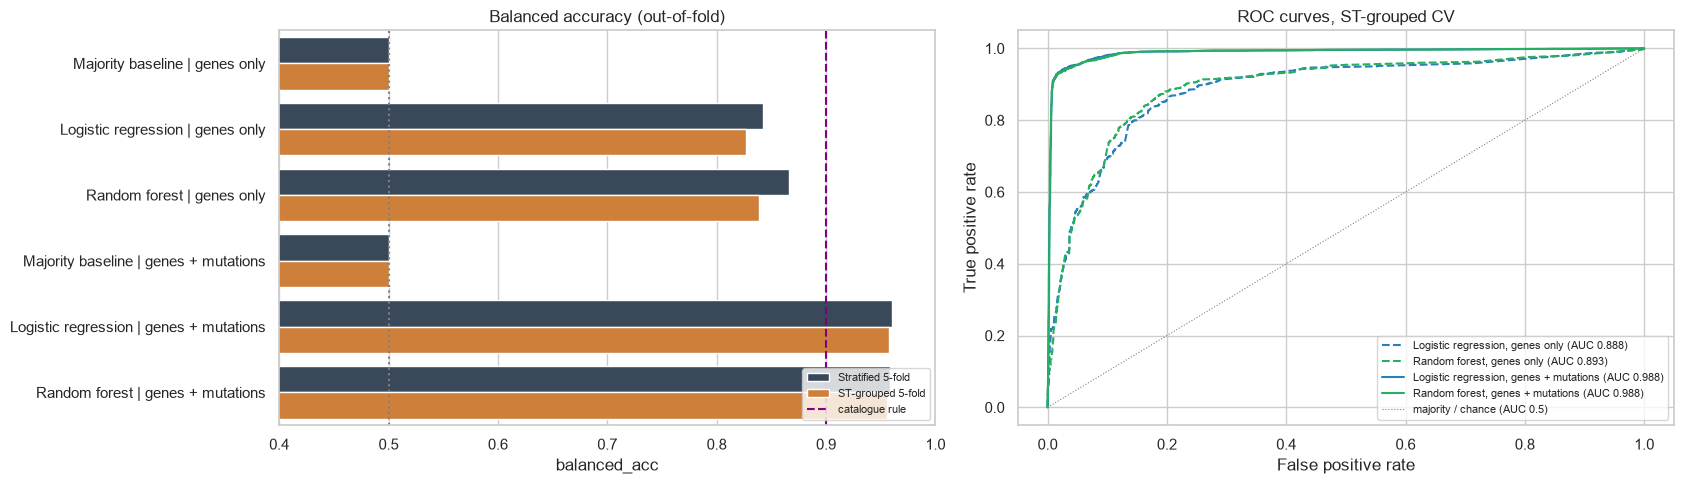

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pp = perf[perf.features != "catalogue rule"].copy()
pp["setup"] = pp.model + " | " + pp.features
sns.barplot(data=pp, y="setup", x="balanced_acc", hue="cv", ax=ax[0], palette=["#34495e", "#e67e22"])
ax[0].axvline(perf.loc[perf.features == "catalogue rule", "balanced_acc"].iloc[0], ls="--", c="purple", label="catalogue rule")
ax[0].axvline(0.5, ls=":", c="grey"); ax[0].set_xlim(0.4, 1); ax[0].legend(fontsize=8, loc="lower right"); ax[0].set_title("Balanced accuracy (out-of-fold)"); ax[0].set_ylabel("")
for fs_name, ls in [("genes only", "--"), ("genes + mutations", "-")]:
    for m_name, c in [("Logistic regression", "#2980b9"), ("Random forest", "#27ae60")]:
        _, prob = oof[("ST-grouped 5-fold", fs_name, m_name)]
        fpr, tpr, _ = roc_curve(y, prob)
        ax[1].plot(fpr, tpr, ls=ls, c=c, label=f"{m_name}, {fs_name} (AUC {roc_auc_score(y, prob):.3f})")
ax[1].plot([0, 1], [0, 1], c="grey", lw=.8, ls=":", label="majority / chance (AUC 0.5)")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(fontsize=8); ax[1].set_title("ROC curves, ST-grouped CV")
plt.tight_layout(); plt.show()

In [25]:
# Does adding mutations significantly improve on genes only? McNemar test on out-of-fold correctness
mc_rows = []
for cv_name in cvs:
    for m_name in ["Logistic regression", "Random forest"]:
        a = oof[(cv_name, "genes only", m_name)][0] == y.values
        b = oof[(cv_name, "genes + mutations", m_name)][0] == y.values
        t = [[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]]
        r = mcnemar(t, exact=False, correction=True)
        mc_rows.append(dict(cv=cv_name, model=m_name, only_genes_correct=t[0][1], only_full_correct=t[1][0], chi2=r.statistic, p=r.pvalue))
    # and best full model vs majority baseline
    a = oof[(cv_name, "genes + mutations", "Majority baseline")][0] == y.values
    b = oof[(cv_name, "genes + mutations", "Random forest")][0] == y.values
    t = [[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]]
    r = mcnemar(t, exact=False, correction=True)
    mc_rows.append(dict(cv=cv_name, model="RF genes+mut vs majority", only_genes_correct=t[0][1], only_full_correct=t[1][0], chi2=r.statistic, p=r.pvalue))
display(pd.DataFrame(mc_rows).rename(columns={"only_genes_correct": "only first model correct", "only_full_correct": "only second model correct"})
        .style.format({"chi2": "{:.1f}", "p": "{:.1e}"}).hide(axis="index"))

cv,model,only first model correct,only second model correct,chi2,p
Stratified 5-fold,Logistic regression,146,1451,1064.8,1.5e-233
Stratified 5-fold,Random forest,155,1234,836.6,5.9e-184
Stratified 5-fold,RF genes+mut vs majority,94,4217,3941.3,0.0e+00
ST-grouped 5-fold,Logistic regression,148,1606,1210.3,3.5e-265
ST-grouped 5-fold,Random forest,158,1529,1112.6,6.1e-244
ST-grouped 5-fold,RF genes+mut vs majority,127,4216,3848.0,0.0e+00


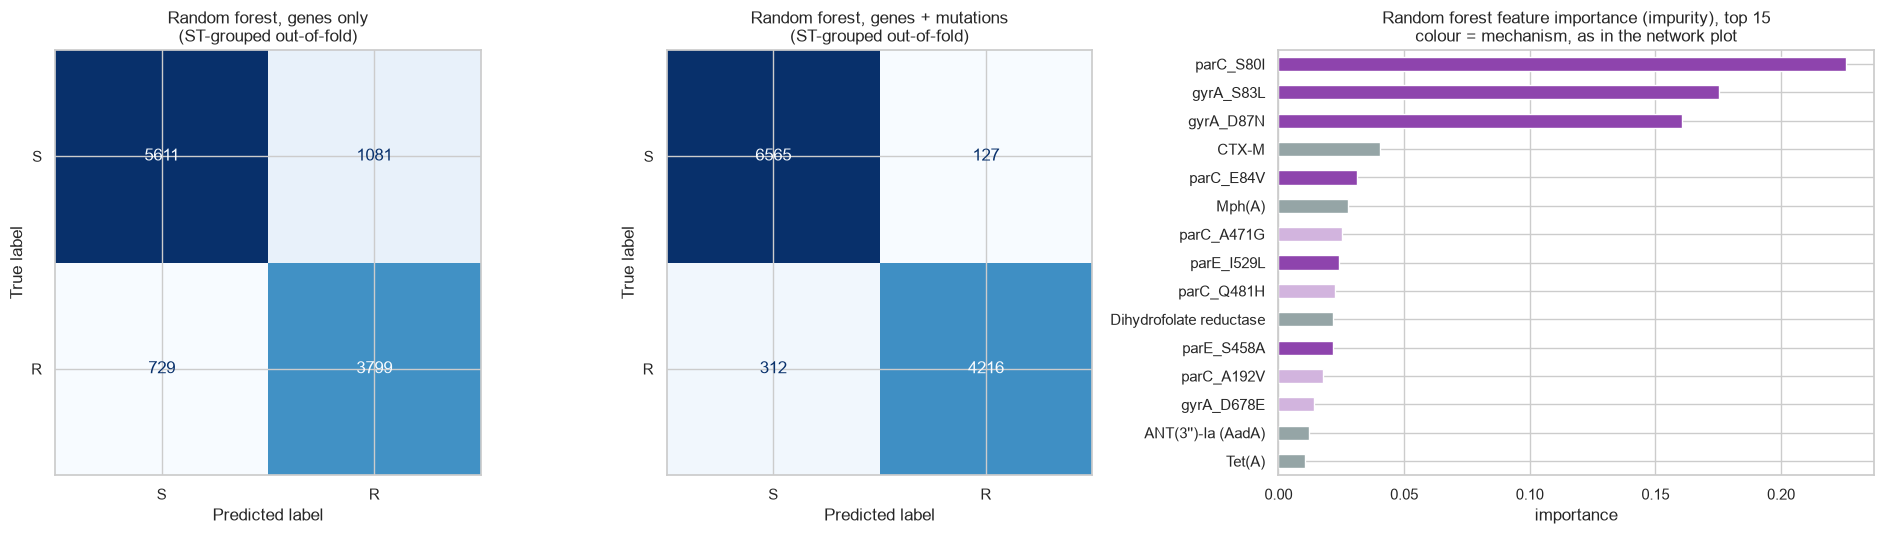

Top logistic-regression coefficients (log-odds):


,QnrB,gyrA_S83L,parC_S80I,QnrB10,parC_S80R,gyrA_D87N,gyrA_D87Y,parC_E84K,parC_E84G,CMY/CMY-2/CFE/LAT
coef,3.58,3.24,3.07,2.86,2.44,1.9,1.74,1.67,1.59,1.3


In [26]:
# Confusion matrices and feature importance for the final model (random forest, genes + mutations), ST-grouped CV
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for i, fs_name in enumerate(["genes only", "genes + mutations"]):
    pred, _ = oof[("ST-grouped 5-fold", fs_name, "Random forest")]
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["S", "R"]).plot(ax=ax[i], cmap="Blues", colorbar=False)
    ax[i].set_title(f"Random forest, {fs_name}\n(ST-grouped out-of-fold)")
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=RNG).fit(X_full, y)
from sklearn.inspection import permutation_importance
imp = pd.Series(rf.feature_importances_, index=X_full.columns).sort_values(ascending=False).head(15)
lr = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(X_full, y)
coef = pd.Series(lr.coef_[0], index=X_full.columns)
imp.iloc[::-1].plot.barh(ax=ax[2], color=[mech_col[mechanism(c)] for c in imp.index[::-1]])
ax[2].set_title("Random forest feature importance (impurity), top 15\ncolour = mechanism, as in the network plot"); ax[2].set_xlabel("importance")
plt.tight_layout(); plt.show()
print("Top logistic-regression coefficients (log-odds):")
display(coef.sort_values(ascending=False).head(10).round(2).to_frame("coef").T)

In [27]:
# Error analysis: what do the misclassified isolates look like?
pred, prob = oof[("ST-grouped 5-fold", "genes + mutations", "Random forest")]
err = meta.assign(pred=pred, prob=prob)
fn = err[(err.pred == 0) & (y == 1)]
fp = err[(err.pred == 1) & (y == 0)]
print(f"False negatives (R predicted S): {len(fn)}; with 0 known QRDR mutations: {(fn.n_qrdr == 0).mean():.0%}")
print(f"False positives (S predicted R): {len(fp)}; carrying >= 2 known QRDR mutations: {(fp.n_qrdr >= 2).mean():.0%}")
fp_mic = mic.loc[mic.index.intersection(fp.index), "value"]
fn_mic = mic.loc[mic.index.intersection(fn.index), "value"]
print("MIC (mg/L) of false positives with a measured MIC:", fp_mic.value_counts().sort_index().to_dict())
print("MIC (mg/L) of false negatives with a measured MIC:", fn_mic.value_counts().sort_index().to_dict())
print("Testing standard of false positives:", ph[ph.genome_id.isin(fp.index)].testing_standard.value_counts(dropna=False).head(5).to_dict())

False negatives (R predicted S): 312; with 0 known QRDR mutations: 30%
False positives (S predicted R): 127; carrying >= 2 known QRDR mutations: 60%
MIC (mg/L) of false positives with a measured MIC: {0.015: 2, 0.12: 1, 0.25: 52, 0.5: 3, 1.0: 2}
MIC (mg/L) of false negatives with a measured MIC: {0.12: 1, 0.25: 1, 0.5: 2, 1.0: 200, 2.0: 16, 4.0: 14, 8.0: 6, 16.0: 3, 64.0: 2, 128.0: 1}
Testing standard of false positives: {'CLSI': 73, nan: 39, 'EUCAST': 34, 'CLSI M100-33rd': 4, 'eucast': 1}


**Interpretation.**

| Model (ST-grouped CV) | Balanced acc. | MCC | ROC-AUC |
|---|---|---|---|
| Majority-class baseline | 0.500 | 0.00 | 0.50 |
| Catalogue rule (no learning) | 0.900 | 0.79 | 0.90 |
| Random forest, genes only | 0.839 | 0.67 | 0.89 |
| Logistic regression, genes + mutations | **0.958** | **0.92** | **0.99** |
| Random forest, genes + mutations | 0.956 | 0.92 | 0.99 |

* **Every model beats the majority baseline** by a wide margin. The baseline gets 59.6% plain accuracy but has zero skill: balanced accuracy 0.50 and MCC 0. The genes + mutations random forest is correct on 4,216 isolates the baseline gets wrong, vs 127 the other way (McNemar p ≈ 0).
* **Adding mutations to genes clearly improves prediction.** Balanced accuracy rises from 0.84 to 0.96 and MCC from 0.67 to 0.92. Under ST-grouped CV, the gene + mutation logistic regression fixes 1,606 isolates the genes-only model gets wrong and loses only 148 (McNemar p ≈ 10⁻²⁶⁵).
* **The genes-only model is better than it "should" be** (balanced accuracy 0.84), even though only about one in five resistant isolates carries a quinolone-active gene. This is co-resistance again: CTX-M, *aac(3)*, *mph(A)* and similar genes flag MDR clones. The genes-only model also loses more performance when whole STs are held out (balanced accuracy 0.866 → 0.839, AUC 0.924 → 0.893). The gene + mutation model barely changes (0.960 → 0.958). So **mutation features capture mechanism and generalise to unseen lineages, while gene-only features partly memorise lineages.**
* **Machine learning adds about 6 points of balanced accuracy over the curated catalogue rule** (0.90 → 0.96). Most of the gain comes from learning that a *single* QRDR mutation is usually not enough (only 19% of single mutants are resistant), which the rule cannot express. Logistic regression and random forest perform the same, so the relationship is close to additive in log-odds, and the simpler, interpretable model is enough. The top features (*gyrA* S83L, *parC* S80I, *qnrB*, *gyrA* D87N, *parC* S80R/E84K/E84G) agree with Stage 5.
* **Error analysis.** There are 312 false negatives. 30% of them carry no known QRDR mutation, so their resistance probably comes from mechanisms we did not measure: efflux regulators such as *marR*/*acrR*/*soxR*, porin loss, or *gyrB* mutations. 200 of them have an MIC of exactly 1 mg/L, right on the breakpoint, where the label itself is uncertain. Of the 127 false positives, 60% carry ≥ 2 known QRDR mutations but are labelled susceptible, mostly with "≤ 0.25 mg/L" MICs. That genotype normally gives an MIC ≥ 4 mg/L, so many of these are likely **phenotype or sample-tracking errors** in the source data rather than model failures.

## 8. Conclusions

**Answer to the research question.** Yes. Known resistance genes and mutations predict ciprofloxacin resistance in *E. coli* very well: balanced accuracy 0.96, MCC 0.92 and ROC-AUC 0.99 in cross-validation that holds out whole sequence types. The majority-class baseline has balanced accuracy 0.50 and MCC 0, and a hand-written catalogue rule reaches 0.90. **The hypothesis is supported in all three parts.** Resistant isolates carry more determinants, the gene + mutation model beats the genes-only model, and both beat the baseline.

**One point per objective**
1. **Dataset (Objective 1).** We assembled 11,220 quality-controlled *E. coli* genomes with lab-measured ciprofloxacin phenotypes from BV-BRC (40.4% resistant), with documented provenance. Along the way we found and corrected a unit error affecting 2,733 disk-diffusion records. Reported labels agree with EUCAST-2024 interpretation of the MIC 99.4% of the time.
2. **Associations (Objective 2).** After Benjamini–Hochberg correction, 92 features are enriched in resistant isolates. The strongest are the QRDR target mutations: *parC* S80I (OR ≈ 950), *gyrA* D87N (≈ 540), *parC* E84V (≈ 390) and *gyrA* S83L (≈ 200). The strongest acquired gene is *aac(6')-Ib-cr* (≈ 71). Resistance tracks the number of QRDR mutations: 2.6% with none, 46% with two and 97 to 99% with three or more.
3. **Classifiers (Objective 3).** Adding mutations raised balanced accuracy from 0.84 (genes only) to 0.96 (McNemar p ≈ 10⁻²⁶⁵). The gene + mutation models held up when entire sequence types were withheld; the genes-only model did not, which shows that gene-only prediction partly relies on lineage.
4. **Biological interpretation (Objective 4).** The top features match CARD and the PointFinder catalogue (mainly target alteration in DNA gyrase and topoisomerase IV). Many significant acquired genes (*bla*CTX-M, *sul2*, *tet(A)*, *aadA*) are co-resistance passengers on MDR plasmids and in high-risk clones, especially ST131 clade C. The NetworkX co-occurrence analysis shows this as three modules: QRDR/ST131, a class 1 integron, and the *aac(6')-Ib-cr*–*bla*OXA-1–*catB* cassette. Some "significant" *parC*/*parE* substitutions are ST131 lineage markers rather than resistance mutations.

**Limitations**
* **Not a random sample.** Five BioProjects contribute 83% of genomes, mostly from Europe and Japan, and ST131 alone is 19%. Prevalences and performance may not transfer to other settings; East Africa is barely represented.
* **Heterogeneous phenotypes.** The data mix MIC and disk-diffusion results and CLSI and EUCAST standards from different years. Borderline MICs (about 1 mg/L) and some likely phenotype or sample errors limit how accurate any genotype model can appear.
* **Incomplete mechanism coverage.** We called mutations only in *gyrA*, *parC* and *parE*. We did not cover *gyrB*, efflux regulators (*marR*, *acrR*, *soxR*), porins or expression changes, which probably explains many of the false negatives. Gene detection relies on BV-BRC's BLAT/NDARO annotation at family level (e.g. "QnrB family").
* **Association is not causation.** Fisher tests ignore population structure, so lineage markers and co-resistance genes appear significant. Grouping CV folds by ST is only a coarse correction for relatedness.
* **Our "known mutation" list** was curated by us from CARD and PointFinder, and its exact contents depend on database version.

**Future steps**
1. Validate externally on an independent collection, for example NCBI Pathogen Detection (AMRFinderPlus) isolates from Kenya and East Africa.
2. Predict the MIC itself by regression rather than a binary label, which would handle the borderline isolates better.
3. Add *gyrB*, *marR*/*acrR*/*soxR* and porin mutations, and run a population-structure-aware GWAS (e.g. pyseer with a phylogeny) to separate causal variants from lineage markers.
4. Extend to other fluoroquinolones (levofloxacin) and other species (*Klebsiella pneumoniae*), and compare with existing tools such as AMRFinderPlus and ResFinder.